#1: Restore Notebook 07 and freeze the final experiment

In [1]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 1:
# Environment + Restore Notebook 07 + Freeze Experiment
# ============================================================

from pathlib import Path
import json
import zipfile
import shutil
import random
import sys

import numpy as np
import pandas as pd
import torch
import sklearn
import transformers
import joblib


# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. Environment
# ============================================================

print("Notebook 08 environment")
print("-----------------------")

print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

print()
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():

    print(
        f"GPU: "
        f"{torch.cuda.get_device_name(0)}"
    )

    print(
        f"GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.2f} GiB"
    )


if not torch.cuda.is_available():

    raise RuntimeError(
        "Notebook 08 requires a CUDA GPU. "
        "Enable a GPU runtime before continuing."
    )


# ============================================================
# 3. Working directories
# ============================================================

NB8_WORK_DIR = Path(
    "notebook08_results"
)

NB8_WORK_DIR.mkdir(
    parents=True,
    exist_ok=True
)


NB7_RESTORE_DIR = Path(
    "notebook07_results_restored"
)


# ============================================================
# 4. Locate / upload Notebook 07 final ZIP
# ============================================================

possible_zip_paths = [

    Path(
        "notebook07_results_final.zip"
    ),

    Path(
        "/content/notebook07_results_final.zip"
    ),
]


NB7_ZIP_PATH = None


for path in possible_zip_paths:

    if path.exists():

        NB7_ZIP_PATH = path
        break


# ------------------------------------------------------------
# Upload if not already present
# ------------------------------------------------------------

if NB7_ZIP_PATH is None:

    print()
    print(
        "Notebook 07 results ZIP not found."
    )

    print(
        "Please upload: "
        "notebook07_results_final.zip"
    )

    from google.colab import files

    uploaded = files.upload()


    uploaded_names = list(
        uploaded.keys()
    )


    matching = [

        name

        for name in uploaded_names

        if name.lower().endswith(".zip")
    ]


    if len(matching) == 0:

        raise FileNotFoundError(
            "No ZIP file was uploaded."
        )


    # Prefer exact expected filename.
    exact_matches = [

        name

        for name in matching

        if Path(name).name
        == "notebook07_results_final.zip"
    ]


    selected_name = (

        exact_matches[0]

        if exact_matches

        else matching[0]
    )


    NB7_ZIP_PATH = Path(
        selected_name
    )


print()
print(
    f"Notebook 07 ZIP: "
    f"{NB7_ZIP_PATH}"
)


# ============================================================
# 5. Extract Notebook 07 artifacts
# ============================================================

if NB7_RESTORE_DIR.exists():

    shutil.rmtree(
        NB7_RESTORE_DIR
    )


NB7_RESTORE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


with zipfile.ZipFile(
    NB7_ZIP_PATH,
    "r"
) as zf:

    zf.extractall(
        NB7_RESTORE_DIR
    )


restored_files = sorted(

    [
        p

        for p in NB7_RESTORE_DIR.rglob("*")

        if p.is_file()
    ]
)


print(
    f"Restored files: "
    f"{len(restored_files)}"
)


# ============================================================
# 6. Helper to locate required artifact
# ============================================================

def find_restored_file(filename):

    matches = list(
        NB7_RESTORE_DIR.rglob(
            filename
        )
    )


    if len(matches) == 0:

        raise FileNotFoundError(
            f"Required Notebook 07 artifact "
            f"not found: {filename}"
        )


    if len(matches) > 1:

        print(
            f"Warning: multiple matches for "
            f"{filename}; using {matches[0]}"
        )


    return matches[0]


# ============================================================
# 7. Required Notebook 07 artifacts
# ============================================================

NB7_MODEL_PATH = (
    find_restored_file(
        "candidate_lifetime_int4_risk_model.joblib"
    )
)


NB7_SUMMARY_PATH = (
    find_restored_file(
        "notebook07_final_summary.json"
    )
)


NB7_LIFETIME_ORACLE_PATH = (
    find_restored_file(
        "lifetime_int4_oracle.csv"
    )
)


NB7_FINAL_SWEEP_PATH = (
    find_restored_file(
        "final_lifetime_policy_sweep.csv"
    )
)


print()
print("Required artifacts")
print("------------------")

print(
    f"Risk model:     "
    f"{NB7_MODEL_PATH}"
)

print(
    f"Summary:        "
    f"{NB7_SUMMARY_PATH}"
)

print(
    f"Lifetime oracle:"
    f" {NB7_LIFETIME_ORACLE_PATH}"
)

print(
    f"Final sweep:    "
    f"{NB7_FINAL_SWEEP_PATH}"
)


# ============================================================
# 8. Load frozen Notebook 07 model
# ============================================================

final_int4_risk_model = (
    joblib.load(
        NB7_MODEL_PATH
    )
)


with open(
    NB7_SUMMARY_PATH,
    "r"
) as f:

    nb7_summary = json.load(
        f
    )


print()
print(
    "Candidate lifetime-risk model loaded."
)


# ============================================================
# 9. FINAL frozen experimental configuration
#
# These values will NOT be tuned using Notebook 08 results.
# ============================================================

MODEL_NAME = (
    "Qwen/Qwen2.5-1.5B"
)

PAGE_SIZE = 16

CACHE_TOKENS = 2048

NUM_PAGES = (
    CACHE_TOKENS
    // PAGE_SIZE
)

DECISION_DELAY_PAGES = 2

DECISION_DELAY_TOKENS = (
    DECISION_DELAY_PAGES
    * PAGE_SIZE
)


CANDIDATE_PAGE_START = 6

CANDIDATE_PAGE_END = 120

CANDIDATE_PAGES = list(
    range(
        CANDIDATE_PAGE_START,
        CANDIDATE_PAGE_END + 1
    )
)


PRIMARY_INT4_SCHEME = (
    "per-vector"
)


# ------------------------------------------------------------
# Frozen practical budgets
# ------------------------------------------------------------

VALIDATION_INT4_BUDGETS = [
    2,
    4,
]

PRIMARY_INT4_BUDGET = 4


# ============================================================
# 10. Important architecture correction
#
# Notebook 08 uses TRUE INT8 as the default.
#
# Pages 0-5 are protected FROM INT4, but they are NOT FP16.
#
# Final architecture:
#
#   selected middle pages -> INT4
#   every other page       -> INT8
#
# There is no learned dynamic FP16 promotion.
# ============================================================

DEFAULT_PRECISION = "INT8"

DYNAMIC_FP16_PROMOTION = False

PREFIX_FP16 = False


# ============================================================
# 11. Freeze dataset segments BEFORE seeing results
#
# Segment 0:
#   original development/reference segment
#
# Segments 1-5:
#   fixed unseen non-overlapping WikiText-2 regions.
#
# 4096-token spacing prevents overlap between the
# 2049-token evaluation windows.
# ============================================================

REFERENCE_SEGMENT_START = 0


UNSEEN_SEGMENT_STARTS = [

    4096,

    8192,

    12288,

    16384,

    20480,
]


ALL_SEGMENT_STARTS = [

    REFERENCE_SEGMENT_START,

    *UNSEEN_SEGMENT_STARTS,
]


SEGMENT_NAMES = [

    "Reference",

    "Unseen_1",

    "Unseen_2",

    "Unseen_3",

    "Unseen_4",

    "Unseen_5",
]


SEGMENT_TOKEN_LENGTH = (
    CACHE_TOKENS + 1
)


assert len(
    SEGMENT_NAMES
) == len(
    ALL_SEGMENT_STARTS
)


# ============================================================
# 12. Logical memory accounting
#
# Final architecture has no FP16 prefix.
# ============================================================

FP16_KIB_PER_PAGE = 448.0

INT8_KIB_PER_PAGE = 224.21875

INT4_KIB_PER_PAGE = 119.0


ALL_FP16_MEMORY_MIB = (

    NUM_PAGES
    * FP16_KIB_PER_PAGE
    / 1024.0
)


UNIFORM_INT8_MEMORY_MIB = (

    NUM_PAGES
    * INT8_KIB_PER_PAGE
    / 1024.0
)


def final_policy_memory_mib(
    int4_budget
):

    int4_budget = int(
        int4_budget
    )


    int8_pages = (
        NUM_PAGES
        - int4_budget
    )


    total_kib = (

        int8_pages
        * INT8_KIB_PER_PAGE

        +

        int4_budget
        * INT4_KIB_PER_PAGE
    )


    return (
        total_kib
        / 1024.0
    )


# ============================================================
# 13. Print frozen experiment
# ============================================================

print()
print(
    "Frozen Notebook 08 experiment"
)

print(
    "-----------------------------"
)

print(
    f"Model:                  "
    f"{MODEL_NAME}"
)

print(
    f"Page size:              "
    f"{PAGE_SIZE} tokens"
)

print(
    f"Cache length:           "
    f"{CACHE_TOKENS} tokens"
)

print(
    f"Logical pages:          "
    f"{NUM_PAGES}"
)

print(
    f"Decision delay:         "
    f"{DECISION_DELAY_TOKENS} tokens"
)

print(
    f"INT4 candidates:        "
    f"{CANDIDATE_PAGE_START}-"
    f"{CANDIDATE_PAGE_END}"
)

print(
    f"Default precision:      "
    f"{DEFAULT_PRECISION}"
)

print(
    f"Dynamic FP16 promotion: "
    f"{DYNAMIC_FP16_PROMOTION}"
)

print(
    f"Primary INT4 budget:    "
    f"L={PRIMARY_INT4_BUDGET}"
)

print(
    f"Unseen segments:        "
    f"{len(UNSEEN_SEGMENT_STARTS)}"
)


print()
print(
    "Logical memory targets"
)

print(
    "----------------------"
)

print(
    f"Uniform FP16: "
    f"{ALL_FP16_MEMORY_MIB:.6f} MiB"
)

print(
    f"Uniform INT8: "
    f"{UNIFORM_INT8_MEMORY_MIB:.6f} MiB"
)


for L in VALIDATION_INT4_BUDGETS:

    memory = (
        final_policy_memory_mib(
            L
        )
    )


    saving_vs_int8 = (

        100.0

        * (

            1.0

            -

            memory
            / UNIFORM_INT8_MEMORY_MIB
        )
    )


    saving_vs_fp16 = (

        100.0

        * (

            1.0

            -

            memory
            / ALL_FP16_MEMORY_MIB
        )
    )


    print()

    print(
        f"L={L}: "
        f"{memory:.6f} MiB"
    )

    print(
        f"     saving vs INT8: "
        f"{saving_vs_int8:.3f}%"
    )

    print(
        f"     saving vs FP16: "
        f"{saving_vs_fp16:.3f}%"
    )


# ============================================================
# 14. Save frozen configuration
# ============================================================

frozen_config = {

    "model":
        MODEL_NAME,

    "page_size":
        PAGE_SIZE,

    "cache_tokens":
        CACHE_TOKENS,

    "decision_delay_pages":
        DECISION_DELAY_PAGES,

    "candidate_page_start":
        CANDIDATE_PAGE_START,

    "candidate_page_end":
        CANDIDATE_PAGE_END,

    "default_precision":
        DEFAULT_PRECISION,

    "dynamic_fp16_promotion":
        DYNAMIC_FP16_PROMOTION,

    "primary_int4_scheme":
        PRIMARY_INT4_SCHEME,

    "validation_int4_budgets":
        VALIDATION_INT4_BUDGETS,

    "primary_int4_budget":
        PRIMARY_INT4_BUDGET,

    "reference_segment_start":
        REFERENCE_SEGMENT_START,

    "unseen_segment_starts":
        UNSEEN_SEGMENT_STARTS,

    "segment_token_length":
        SEGMENT_TOKEN_LENGTH,
}


with open(

    NB8_WORK_DIR
    / "frozen_notebook08_config.json",

    "w"
) as f:

    json.dump(
        frozen_config,
        f,
        indent=2
    )


print()
print(
    "Cell 1 complete."
)

print(
    "Notebook 08 configuration is now frozen."
)

print(
    "Do not change segments, L budgets, or "
    "the predictor after inspecting unseen results."
)

Notebook 08 environment
-----------------------
Python:       3.13.15
PyTorch:      2.11.0+cu128
Transformers: 5.16.1
scikit-learn: 1.6.1

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GiB

Notebook 07 results ZIP not found.
Please upload: notebook07_results_final.zip


Saving notebook07_results_final.zip to notebook07_results_final.zip

Notebook 07 ZIP: notebook07_results_final.zip
Restored files: 40

Required artifacts
------------------
Risk model:     notebook07_results_restored/candidate_lifetime_int4_risk_model.joblib
Summary:        notebook07_results_restored/notebook07_final_summary.json
Lifetime oracle: notebook07_results_restored/lifetime_int4_oracle.csv
Final sweep:    notebook07_results_restored/final_lifetime_policy_sweep.csv

Candidate lifetime-risk model loaded.

Frozen Notebook 08 experiment
-----------------------------
Model:                  Qwen/Qwen2.5-1.5B
Page size:              16 tokens
Cache length:           2048 tokens
Logical pages:          128
Decision delay:         32 tokens
INT4 candidates:        6-120
Default precision:      INT8
Dynamic FP16 promotion: False
Primary INT4 budget:    L=4
Unseen segments:        5

Logical memory targets
----------------------
Uniform FP16: 56.000000 MiB
Uniform INT8: 28.027344 MiB



#2: Load Qwen, WikiText-2, and prepare the six frozen segments

In [2]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 2:
# Load Model + WikiText-2 + Frozen Evaluation Segments
# ============================================================

import gc
import pandas as pd
import torch

from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)


# ============================================================
# 1. Clear unused memory before model load
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


DEVICE = torch.device("cuda")
DTYPE = torch.float16


# ============================================================
# 2. Load tokenizer
#
# Preserve the exact model/tokenizer used in previous notebooks.
# ============================================================

print("Loading tokenizer...")
print("--------------------")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


print(
    f"Tokenizer loaded: "
    f"{MODEL_NAME}"
)


# ============================================================
# 3. Load Qwen2.5-1.5B
#
# Keep SDPA for the final quality evaluation.
# No eager-attention analysis is needed in Notebook 08.
# ============================================================

print()
print("Loading model...")
print("----------------")


model = AutoModelForCausalLM.from_pretrained(

    MODEL_NAME,

    dtype=DTYPE,

    device_map={
        "": 0
    },

    low_cpu_mem_usage=True,

    attn_implementation="sdpa",
)


model.eval()


print(
    f"Model loaded on: "
    f"{model.device}"
)


# ============================================================
# 4. Verify architecture
# ============================================================

config = model.config


NUM_LAYERS = (
    config.num_hidden_layers
)

NUM_ATTENTION_HEADS = (
    config.num_attention_heads
)

NUM_KV_HEADS = getattr(

    config,

    "num_key_value_heads",

    NUM_ATTENTION_HEADS
)


HEAD_DIM = getattr(

    config,

    "head_dim",

    (
        config.hidden_size
        // NUM_ATTENTION_HEADS
    )
)


print()
print("Model architecture")
print("------------------")

print(
    f"Layers:          "
    f"{NUM_LAYERS}"
)

print(
    f"Attention heads: "
    f"{NUM_ATTENTION_HEADS}"
)

print(
    f"KV heads:        "
    f"{NUM_KV_HEADS}"
)

print(
    f"Hidden size:     "
    f"{config.hidden_size}"
)

print(
    f"Head dimension:  "
    f"{HEAD_DIM}"
)

print(
    f"Model dtype:     "
    f"{next(model.parameters()).dtype}"
)


# ------------------------------------------------------------
# Expected architecture from Notebooks 01-07
# ------------------------------------------------------------

assert NUM_LAYERS == 28
assert NUM_ATTENTION_HEADS == 12
assert NUM_KV_HEADS == 2
assert config.hidden_size == 1536
assert HEAD_DIM == 128


print()
print(
    "Architecture validation PASSED."
)


# ============================================================
# 5. Load WikiText-2 test split
#
# IMPORTANT:
# This exactly preserves the earlier notebook protocol:
#
#   Salesforce/wikitext
#   wikitext-2-raw-v1
#   split = test
#
# and:
#
#   test_text = \"\\n\\n\".join(dataset[\"text\"])
#
# ============================================================

print()
print("Loading WikiText-2...")
print("---------------------")


test_dataset = load_dataset(

    "Salesforce/wikitext",

    "wikitext-2-raw-v1",

    split="test"
)


test_text = "\n\n".join(
    test_dataset["text"]
)


print(
    f"Dataset rows: "
    f"{len(test_dataset):,}"
)


# ============================================================
# 6. Tokenize exactly as previous notebooks
# ============================================================

print()
print(
    "Tokenizing full test split..."
)


encodings = tokenizer(

    test_text,

    return_tensors="pt",

    add_special_tokens=False
)


# Keep the complete dataset on CPU.
all_test_ids = (
    encodings.input_ids
    .cpu()
)


TOTAL_TEST_TOKENS = (
    all_test_ids.shape[1]
)


print(
    f"Total WikiText-2 test tokens: "
    f"{TOTAL_TEST_TOKENS:,}"
)


# ------------------------------------------------------------
# Strong reproducibility check
#
# Previous notebooks measured exactly 299,078 tokens.
# ------------------------------------------------------------

EXPECTED_TOTAL_TEST_TOKENS = 299_078


if (
    TOTAL_TEST_TOKENS
    != EXPECTED_TOTAL_TEST_TOKENS
):

    raise RuntimeError(

        "Tokenization mismatch. "

        f"Expected "
        f"{EXPECTED_TOTAL_TEST_TOKENS:,} "
        f"tokens from the previous notebooks, "

        f"but obtained "
        f"{TOTAL_TEST_TOKENS:,}. "

        "Stop here before running validation."
    )


print(
    "Tokenization validation PASSED."
)


# ============================================================
# 7. Construct the FROZEN segments
#
# Each segment contains:
#
#   2048 evaluated input positions
#   + 1 next-token target
#
# Total = 2049 tokens.
#
# The original/reference segment begins at token 0.
# The five validation segments were frozen in Cell 1.
# ============================================================

segment_rows = []

SEGMENT_IDS_CPU = {}


for name, start in zip(
    SEGMENT_NAMES,
    ALL_SEGMENT_STARTS
):

    end = (
        start
        + SEGMENT_TOKEN_LENGTH
    )


    if end > TOTAL_TEST_TOKENS:

        raise RuntimeError(

            f"Segment {name} exceeds "
            f"the WikiText token range."
        )


    ids = (

        all_test_ids[
            :,
            start:end
        ]

        .clone()
    )


    assert (
        ids.shape[1]
        == SEGMENT_TOKEN_LENGTH
    )


    SEGMENT_IDS_CPU[
        name
    ] = ids


    segment_rows.append({

        "Segment":
            name,

        "Start_Token":
            int(start),

        "End_Token_Inclusive":
            int(end - 1),

        "Total_Tokens":
            int(ids.shape[1]),

        "Evaluated_Cache_Tokens":
            CACHE_TOKENS,

        "Is_Reference":
            bool(
                name == "Reference"
            ),
    })


segment_manifest_df = pd.DataFrame(
    segment_rows
)


# ============================================================
# 8. Check for overlap
# ============================================================

sorted_segments = (

    segment_manifest_df

    .sort_values(
        "Start_Token"
    )

    .reset_index(
        drop=True
    )
)


for i in range(
    len(sorted_segments) - 1
):

    current_end = (

        sorted_segments
        .iloc[i][
            "End_Token_Inclusive"
        ]
    )


    next_start = (

        sorted_segments
        .iloc[i + 1][
            "Start_Token"
        ]
    )


    assert (
        current_end
        < next_start
    )


print()
print(
    "Segment overlap check PASSED."
)


# ============================================================
# 9. Segment manifest
# ============================================================

print()
print(
    "Frozen evaluation segments"
)

print(
    "--------------------------"
)


display(
    segment_manifest_df
)


# ============================================================
# 10. Basic token-content sanity preview
#
# Only a small preview is shown.
# This is NOT used to select/change segments.
# ============================================================

preview_rows = []


for name in SEGMENT_NAMES:

    ids = (
        SEGMENT_IDS_CPU[
            name
        ]
    )


    preview_text = tokenizer.decode(

        ids[
            0,
            :32
        ],

        skip_special_tokens=False
    )


    # Keep display compact.
    preview_text = (
        preview_text
        .replace(
            "\n",
            "\\n"
        )
    )


    preview_rows.append({

        "Segment":
            name,

        "First_32_Tokens_Preview":
            preview_text[:180],
    })


segment_preview_df = pd.DataFrame(
    preview_rows
)


print()
print(
    "Small content sanity preview"
)

print(
    "----------------------------"
)


display(
    segment_preview_df
)


# ============================================================
# 11. GPU memory after loading
# ============================================================

allocated_gib = (

    torch.cuda.memory_allocated()
    / 2**30
)

reserved_gib = (

    torch.cuda.memory_reserved()
    / 2**30
)


print()
print(
    "GPU memory after model load"
)

print(
    "---------------------------"
)

print(
    f"Allocated: "
    f"{allocated_gib:.3f} GiB"
)

print(
    f"Reserved:  "
    f"{reserved_gib:.3f} GiB"
)


# ============================================================
# 12. Save segment manifest
# ============================================================

segment_manifest_path = (

    NB8_WORK_DIR
    / "frozen_segment_manifest.csv"
)


segment_manifest_df.to_csv(

    segment_manifest_path,

    index=False
)


print()
print(
    "Cell 2 complete."
)

print(
    f"Segment manifest saved to: "
    f"{segment_manifest_path}"
)

print(
    "Reference + 5 unseen segments "
    "are ready for evaluation."
)

Loading tokenizer...
--------------------


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Total WikiText-2 test tokens: 299,078
Tokenization validation PASSED.

Segment overlap check PASSED.

Frozen evaluation segments
--------------------------


,Segment,Start_Token,End_Token_Inclusive,Total_Tokens,Evaluated_Cache_Tokens,Is_Reference
0,Reference,0,2048,2049,2048,True
1,Unseen_1,4096,6144,2049,2048,False
2,Unseen_2,8192,10240,2049,2048,False
3,Unseen_3,12288,14336,2049,2048,False
4,Unseen_4,16384,18432,2049,2048,False
5,Unseen_5,20480,22528,2049,2048,False



Small content sanity preview
----------------------------


,Segment,First_32_Tokens_Preview
0,Reference,\n\n = Robert Boulter = \n\n\n\n\n Robert Boul...
1,Unseen_1,""" Let us all be less selfish , let us all do ..."
2,Unseen_2,\n\n\n\n\n = = Commercial performance = = \n\...
3,Unseen_3,) at a speed of 14 knots ( 26 km / h ; 16 mph...
4,Unseen_4,group ever had all of its intended aircraft ....
5,Unseen_5,"icians "" is considered to be the greatest Univ..."



GPU memory after model load
---------------------------
Allocated: 2.875 GiB
Reserved:  2.932 GiB

Cell 2 complete.
Segment manifest saved to: notebook08_results/frozen_segment_manifest.csv
Reference + 5 unseen segments are ready for evaluation.


#3: Exact quantization helpers + true-INT8 streaming evaluator

In [3]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 3:
# Exact Quantization Helpers
# + True-INT8 Streaming Evaluator
#
# Final architecture:
#
#   ALL completed pages -> INT8 by default
#   selected pages      -> INT4 after 32-token delay
#
# Pages 0-5 are protected FROM INT4 selection,
# but they are still INT8.
#
# NO FP16 prefix.
# NO FP16 shadow.
# NO dynamic FP16 promotion.
# ============================================================

import gc
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import DynamicCache


# ============================================================
# 1. Exact symmetric quantizer from earlier notebooks
# ============================================================

def symmetric_quantize(
    tensor,
    num_bits,
):

    qmax = (
        2 ** (num_bits - 1)
        - 1
    )

    qmin = -qmax

    x = tensor.float()

    max_abs = (
        x.abs().max()
    )


    if max_abs == 0:

        scale = torch.tensor(
            1.0,
            device=x.device,
            dtype=torch.float32,
        )

    else:

        scale = (
            max_abs
            / qmax
        )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax,
    )

    q = q.to(
        torch.int8
    )


    return (
        q,
        scale
    )


def symmetric_dequantize(
    q,
    scale,
    dtype,
):

    return (
        q.float()
        * scale
    ).to(
        dtype
    )


# ============================================================
# 2. Per-vector INT4
#
# Exact selected Notebook 05 semantics:
#
# each [head, token] vector of length head_dim
# receives its own symmetric scale.
# ============================================================

def quant_dequant_per_vector(
    tensor,
    num_bits=4,
):

    qmax = (
        2 ** (num_bits - 1)
        - 1
    )

    qmin = -qmax


    x = tensor.float()


    max_abs = (

        x.abs()

        .amax(
            dim=-1,
            keepdim=True
        )
    )


    scale = (
        max_abs
        / qmax
    )


    # Preserve exact previous behavior:
    # zero vectors use scale 1.
    scale = torch.where(

        max_abs == 0,

        torch.ones_like(
            scale
        ),

        scale
    )


    q = torch.round(
        x / scale
    )


    q = torch.clamp(
        q,
        qmin,
        qmax,
    )


    dq = (
        q * scale
    ).to(
        tensor.dtype
    )


    return (
        dq,
        scale.numel()
    )


# ============================================================
# 3. Quantize one completed logical page in-place
# ============================================================

@torch.no_grad()
def quantize_cache_page_inplace(
    cache,
    start_token,
    end_token,
    precision,
):

    if precision == "FP16":
        return


    for layer_idx in range(
        len(cache.layers)
    ):

        layer = cache.layers[
            layer_idx
        ]


        # ----------------------------------------------------
        # Slice logical page
        # Shape:
        # [B, H_KV, PAGE_SIZE, HEAD_DIM]
        # ----------------------------------------------------

        k_page = (
            layer.keys[
                :,
                :,
                start_token:end_token,
                :
            ]
        )


        v_page = (
            layer.values[
                :,
                :,
                start_token:end_token,
                :
            ]
        )


        # ----------------------------------------------------
        # INT8:
        # one scale for complete K page,
        # one scale for complete V page,
        # independently per layer.
        # ----------------------------------------------------

        if precision == "INT8":

            k_q, k_scale = (
                symmetric_quantize(
                    k_page,
                    num_bits=8,
                )
            )


            v_q, v_scale = (
                symmetric_quantize(
                    v_page,
                    num_bits=8,
                )
            )


            k_dq = (
                symmetric_dequantize(
                    k_q,
                    k_scale,
                    k_page.dtype,
                )
            )


            v_dq = (
                symmetric_dequantize(
                    v_q,
                    v_scale,
                    v_page.dtype,
                )
            )


            k_page.copy_(
                k_dq
            )


            v_page.copy_(
                v_dq
            )


        # ----------------------------------------------------
        # INT4:
        # selected final scheme = per-vector.
        #
        # Important:
        # target page is already INT8 before this occurs.
        # Therefore this represents:
        #
        # INT8 approximation -> per-vector INT4 approximation.
        # ----------------------------------------------------

        elif precision == "INT4":

            k_dq, _ = (
                quant_dequant_per_vector(
                    k_page,
                    num_bits=4,
                )
            )


            v_dq, _ = (
                quant_dequant_per_vector(
                    v_page,
                    num_bits=4,
                )
            )


            k_page.copy_(
                k_dq
            )


            v_page.copy_(
                v_dq
            )


        else:

            raise ValueError(
                f"Unknown precision: "
                f"{precision}"
            )


# ============================================================
# 4. True streaming evaluator
#
# Evaluates exactly 2048 next-token targets.
#
# For INT8/default policy:
#
#   1. process completed page in FP16 arithmetic
#   2. append it to cache
#   3. immediately store its cache approximation as INT8
#
# For selected INT4 page p:
#
#   p is INT8 during the 32-token observation delay
#
#   after page p+2 is completed:
#
#       p: INT8 -> INT4
#
#   p then stays INT4 for the remainder of the sequence.
#
# No page is ever restored to FP16.
# ============================================================

@torch.no_grad()
def evaluate_true_int8_stream(
    input_ids,
    policy_name,
    int4_pages=None,
    quantize_default_int8=True,
):

    if int4_pages is None:
        int4_pages = set()

    else:
        int4_pages = set(
            int(p)
            for p in int4_pages
        )


    # --------------------------------------------------------
    # Strong policy validation
    # --------------------------------------------------------

    for page in int4_pages:

        assert (
            CANDIDATE_PAGE_START
            <= page
            <= CANDIDATE_PAGE_END
        )


    input_ids = input_ids.to(
        DEVICE
    )


    assert (
        input_ids.shape[1]
        >= CACHE_TOKENS + 1
    )


    cache = DynamicCache(
        config=model.config
    )


    total_nll = 0.0
    total_targets = 0


    demoted_pages = set()


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    start_time = time.time()


    # ========================================================
    # Stream exactly 128 logical pages
    # ========================================================

    for page_idx in range(
        NUM_PAGES
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        current_ids = (
            input_ids[
                :,
                start:end
            ]
        )


        targets = (
            input_ids[
                :,
                start + 1:end + 1
            ]
        )


        assert (
            current_ids.shape[1]
            == PAGE_SIZE
        )

        assert (
            targets.shape[1]
            == PAGE_SIZE
        )


        cache_position = torch.arange(

            start,
            end,

            device=DEVICE,
            dtype=torch.long,
        )


        attention_mask = torch.ones(

            (
                input_ids.shape[0],
                end
            ),

            dtype=torch.long,
            device=DEVICE,
        )


        outputs = model(

            input_ids=current_ids,

            attention_mask=attention_mask,

            past_key_values=cache,

            use_cache=True,

            cache_position=cache_position,

            return_dict=True,
        )


        # Some Transformers versions return the same cache,
        # others return a cache object explicitly.
        if (
            outputs.past_key_values
            is not None
        ):

            cache = (
                outputs.past_key_values
            )


        logits = (
            outputs.logits
        )


        # ----------------------------------------------------
        # Score all PAGE_SIZE next-token targets.
        #
        # Last token of the current page predicts the first
        # token after that page, so page boundaries are kept.
        # ----------------------------------------------------

        chunk_nll = F.cross_entropy(

            logits
            .float()
            .reshape(
                -1,
                logits.shape[-1]
            ),

            targets
            .reshape(-1),

            reduction="sum",
        )


        total_nll += float(
            chunk_nll.item()
        )


        total_targets += int(
            targets.numel()
        )


        # ----------------------------------------------------
        # DEFAULT STORAGE:
        #
        # Every page becomes INT8 after completion.
        #
        # This includes Pages 0-5.
        # ----------------------------------------------------

        if quantize_default_int8:

            quantize_cache_page_inplace(

                cache,

                start_token=start,

                end_token=end,

                precision="INT8",
            )


        # ----------------------------------------------------
        # DELAYED INT4 DECISION
        #
        # Once page (p+2) has completed,
        # make decision for page p.
        # ----------------------------------------------------

        decision_target_page = (

            page_idx
            - DECISION_DELAY_PAGES
        )


        if (

            decision_target_page
            in int4_pages

            and

            decision_target_page
            not in demoted_pages
        ):

            target_start = (

                decision_target_page
                * PAGE_SIZE
            )


            target_end = (

                target_start
                + PAGE_SIZE
            )


            quantize_cache_page_inplace(

                cache,

                start_token=target_start,

                end_token=target_end,

                precision="INT4",
            )


            demoted_pages.add(
                decision_target_page
            )


    # ========================================================
    # End stream
    # ========================================================

    if torch.cuda.is_available():
        torch.cuda.synchronize()


    runtime_seconds = (
        time.time()
        - start_time
    )


    assert (
        total_targets
        == CACHE_TOKENS
    )


    assert (
        demoted_pages
        == int4_pages
    )


    mean_nll = (
        total_nll
        / total_targets
    )


    ppl = math.exp(
        mean_nll
    )


    return {

        "Policy":
            policy_name,

        "PPL":
            float(ppl),

        "NLL":
            float(mean_nll),

        "Targets":
            int(total_targets),

        "INT4_Pages":
            int(
                len(int4_pages)
            ),

        "Runtime_Seconds":
            float(
                runtime_seconds
            ),
    }


# ============================================================
# 5. Reference-segment baseline validation
#
# This is the methodological correction we need before
# touching the unseen segments.
# ============================================================

reference_ids = (
    SEGMENT_IDS_CPU[
        "Reference"
    ]
)


print(
    "Running corrected reference baselines..."
)

print(
    "----------------------------------------"
)


gc.collect()
torch.cuda.empty_cache()


reference_fp16 = (
    evaluate_true_int8_stream(

        input_ids=reference_ids,

        policy_name="Reference_FP16",

        int4_pages=set(),

        quantize_default_int8=False,
    )
)


gc.collect()
torch.cuda.empty_cache()


reference_uniform_int8 = (
    evaluate_true_int8_stream(

        input_ids=reference_ids,

        policy_name="Reference_Uniform_INT8",

        int4_pages=set(),

        quantize_default_int8=True,
    )
)


print()

print(
    f"Reference FP16 PPL:       "
    f"{reference_fp16['PPL']:.6f}"
)

print(
    f"Reference uniform INT8:   "
    f"{reference_uniform_int8['PPL']:.6f}"
)


print()

print(
    "Previous Notebook 05 "
    "uniform-INT8 reference:"
)

print(
    "6.980423"
)


int8_difference = abs(

    reference_uniform_int8[
        "PPL"
    ]

    - 6.980423
)


print(
    f"Absolute difference:      "
    f"{int8_difference:.6f}"
)


# ------------------------------------------------------------
# Allow small numerical/library-version differences,
# but stop if something is materially wrong.
# ------------------------------------------------------------

INT8_VALIDATION_TOLERANCE = 0.05


if (
    int8_difference
    > INT8_VALIDATION_TOLERANCE
):

    raise RuntimeError(

        "Corrected uniform INT8 baseline does not reproduce "
        "the previous result closely enough. "

        "Do not continue to unseen validation."
    )


print()
print(
    "True-INT8 baseline validation PASSED."
)


# ============================================================
# 6. Confirm prefix pages really are INT8 conceptually
# ============================================================

print()
print(
    "Final architecture validation"
)

print(
    "-----------------------------"
)

print(
    "Pages 0-5:   INT8 "
    "(protected from INT4 only)"
)

print(
    "Pages 6-120: INT8 by default, "
    "eligible for selected INT4"
)

print(
    "Pages 121-127: INT8"
)

print(
    "Dynamic FP16 pages: 0"
)

print(
    "FP16 shadow pages:  0"
)


# ============================================================
# 7. Save corrected baseline
# ============================================================

reference_baseline_df = pd.DataFrame([

    reference_fp16,

    reference_uniform_int8,
])


reference_baseline_df[
    "Logical_KV_Memory_MiB"
] = [

    ALL_FP16_MEMORY_MIB,

    UNIFORM_INT8_MEMORY_MIB,
]


reference_baseline_path = (

    NB8_WORK_DIR
    / "corrected_reference_baselines.csv"
)


reference_baseline_df.to_csv(

    reference_baseline_path,

    index=False
)


display(
    reference_baseline_df
)


print()
print(
    "Cell 3 complete."
)

print(
    f"Saved to: "
    f"{reference_baseline_path}"
)

Running corrected reference baselines...
----------------------------------------

Reference FP16 PPL:       6.967845
Reference uniform INT8:   6.974613

Previous Notebook 05 uniform-INT8 reference:
6.980423
Absolute difference:      0.005810

True-INT8 baseline validation PASSED.

Final architecture validation
-----------------------------
Pages 0-5:   INT8 (protected from INT4 only)
Pages 6-120: INT8 by default, eligible for selected INT4
Pages 121-127: INT8
Dynamic FP16 pages: 0
FP16 shadow pages:  0


,Policy,PPL,NLL,Targets,INT4_Pages,Runtime_Seconds,Logical_KV_Memory_MiB
0,Reference_FP16,6.967845,1.941306,2048,0,8.983742,56.000000
1,Reference_Uniform_INT8,6.974613,1.942277,2048,0,6.299697,28.027344



Cell 3 complete.
Saved to: notebook08_results/corrected_reference_baselines.csv


#4: Corrected reference segment: recompute deployable signal and test frozen \(L=2,L=4\)

By “corrected frozen model” I mean the small **page-risk predictor** we trained at the end of Notebook 07 — not Qwen itself.

The language model is still:

$$
\boxed{\text{Qwen2.5-1.5B}}
$$

The “frozen model” is this saved predictor:

```text
candidate_lifetime_int4_risk_model.joblib
```

It is a simple **Ridge regression** model trained on Notebook 07 pages. Its input is:

$$
\boxed{\texttt{V\_NRMSE\_Max}}
$$

which measures how much the Value vectors of a page are distorted when simulating:

$$
INT8 \rightarrow INT4.
$$

Its target during Notebook 07 training was:

$$
\boxed{\texttt{Affected\_Mean\_Delta\_NLL}}
$$

which estimates the average future-token quality damage caused by keeping that page in INT4.

So its logic is basically:

$$
\text{V quantization distortion}
\rightarrow
\text{predicted INT4 risk}.
$$

Then in Notebook 08 we multiply that predicted per-token risk by the number of remaining future tokens:

$$
\text{Predicted total risk}
=
\text{Predicted normalized risk}
\times
\text{Remaining lifetime}.
$$

Pages with the **lowest predicted total risk** are selected for INT4.

“Frozen” means we are **not retraining or tuning it using Notebook 08's unseen segments**. We trained it once on Notebook 07 and now test whether it generalizes. That separation is important scientifically.

So there are really two models involved:

$$
\boxed{\text{Qwen2.5-1.5B}}
$$

= the LLM being compressed/evaluated

and

$$
\boxed{\text{Ridge page-risk predictor}}
$$

= the tiny model deciding which KV pages may be safe to put in INT4.


In [4]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 4:
#
# Corrected Reference-Segment Policy
#
# 1. Extract V_NRMSE_Max under TRUE INT8 storage
# 2. Apply frozen Notebook 07 risk model
# 3. Convert normalized risk -> lifetime risk
# 4. Select frozen L=2 and L=4 budgets
# 5. Evaluate actual end-to-end PPL
#
# IMPORTANT:
# This reference segment contributed to Notebook 07 training.
# Therefore this cell is a correction/sanity check,
# NOT unseen generalization evidence.
# ============================================================

import gc
import json
import time

import numpy as np
import pandas as pd
import torch

from transformers import DynamicCache


# ============================================================
# 1. Extract deployable V_NRMSE_Max
#
# Stream remains uniformly INT8.
#
# At the delayed decision point for candidate page p:
#
#   - page p has already been stored as INT8
#   - simulate p -> per-vector INT4
#   - measure V reconstruction NRMSE
#   - DO NOT modify the real cache
#
# This matches the low-bit signal used by the frozen
# Notebook 07 candidate model.
# ============================================================

@torch.no_grad()
def extract_true_int8_v_nrmse_features(
    input_ids,
    segment_name,
):

    input_ids = input_ids.to(
        DEVICE
    )

    cache = DynamicCache(
        config=model.config
    )

    rows = []


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    start_time = time.time()


    for page_idx in range(
        NUM_PAGES
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        current_ids = (
            input_ids[
                :,
                start:end
            ]
        )


        cache_position = torch.arange(

            start,
            end,

            device=DEVICE,
            dtype=torch.long,
        )


        attention_mask = torch.ones(

            (
                input_ids.shape[0],
                end
            ),

            device=DEVICE,
            dtype=torch.long,
        )


        outputs = model(

            input_ids=current_ids,

            attention_mask=attention_mask,

            past_key_values=cache,

            use_cache=True,

            cache_position=cache_position,

            return_dict=True,
        )


        if outputs.past_key_values is not None:

            cache = (
                outputs.past_key_values
            )


        # ----------------------------------------------------
        # TRUE default architecture:
        # every completed page -> INT8.
        # ----------------------------------------------------

        quantize_cache_page_inplace(

            cache,

            start_token=start,

            end_token=end,

            precision="INT8",
        )


        # ----------------------------------------------------
        # Delayed decision:
        #
        # current page = p + 2
        # inspect target page p.
        # ----------------------------------------------------

        target_page = (

            page_idx
            - DECISION_DELAY_PAGES
        )


        if not (

            CANDIDATE_PAGE_START
            <= target_page
            <= CANDIDATE_PAGE_END

        ):

            continue


        target_start = (

            target_page
            * PAGE_SIZE
        )


        target_end = (

            target_start
            + PAGE_SIZE
        )


        layer_v_nrmse = []


        # ====================================================
        # Measure INT8 -> simulated per-vector INT4
        # distortion for Values in every layer.
        # ====================================================

        for layer_idx in range(
            len(cache.layers)
        ):

            layer = cache.layers[
                layer_idx
            ]


            v_page = (

                layer.values[
                    :,
                    :,
                    target_start:target_end,
                    :
                ]
            )


            v_fp32 = (
                v_page.float()
            )


            v_int4_dq, _ = (
                quant_dequant_per_vector(

                    v_page,

                    num_bits=4,
                )
            )


            error = (

                v_fp32

                -

                v_int4_dq.float()
            )


            rmse = torch.sqrt(

                torch.mean(
                    error ** 2
                )
            )


            rms = torch.sqrt(

                torch.mean(
                    v_fp32 ** 2
                )
            )


            if float(rms.item()) == 0.0:

                nrmse = 0.0

            else:

                nrmse = float(

                    (
                        rmse
                        / rms
                    ).item()
                )


            layer_v_nrmse.append(
                nrmse
            )


        assert (
            len(layer_v_nrmse)
            == NUM_LAYERS
        )


        decision_end = (

            (
                target_page
                + DECISION_DELAY_PAGES
                + 1
            )

            * PAGE_SIZE
        )


        remaining_targets = (

            CACHE_TOKENS
            - decision_end
        )


        assert (
            remaining_targets
            > 0
        )


        rows.append({

            "Segment":
                segment_name,

            "Page":
                int(
                    target_page
                ),

            "Start_Token":
                int(
                    target_start
                ),

            "End_Token":
                int(
                    target_end - 1
                ),

            "Remaining_Affected_Targets":
                int(
                    remaining_targets
                ),

            "V_NRMSE_Mean":
                float(
                    np.mean(
                        layer_v_nrmse
                    )
                ),

            "V_NRMSE_Std":
                float(
                    np.std(
                        layer_v_nrmse
                    )
                ),

            "V_NRMSE_Max":
                float(
                    np.max(
                        layer_v_nrmse
                    )
                ),
        })


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    feature_df = (

        pd.DataFrame(
            rows
        )

        .sort_values(
            "Page"
        )

        .reset_index(
            drop=True
        )
    )


    assert (
        len(feature_df)
        == len(CANDIDATE_PAGES)
    )


    assert np.array_equal(

        feature_df[
            "Page"
        ].to_numpy(),

        np.array(
            CANDIDATE_PAGES
        )
    )


    runtime = (
        time.time()
        - start_time
    )


    return (
        feature_df,
        runtime
    )


# ============================================================
# 2. Extract reference features
# ============================================================

print(
    "Extracting corrected reference features..."
)

print(
    "-----------------------------------------"
)


gc.collect()
torch.cuda.empty_cache()


reference_feature_df, feature_runtime = (
    extract_true_int8_v_nrmse_features(

        input_ids=reference_ids,

        segment_name="Reference",
    )
)


print(
    f"Candidate pages extracted: "
    f"{len(reference_feature_df)}"
)

print(
    f"Feature runtime: "
    f"{feature_runtime:.2f} sec"
)


print()
print(
    "V_NRMSE_Max summary"
)

print(
    "-------------------"
)

print(
    f"Min:    "
    f"{reference_feature_df['V_NRMSE_Max'].min():.6f}"
)

print(
    f"Median: "
    f"{reference_feature_df['V_NRMSE_Max'].median():.6f}"
)

print(
    f"Mean:   "
    f"{reference_feature_df['V_NRMSE_Max'].mean():.6f}"
)

print(
    f"Max:    "
    f"{reference_feature_df['V_NRMSE_Max'].max():.6f}"
)


# ============================================================
# 3. Apply FROZEN Notebook 07 model
#
# Model predicts normalized per-future-token INT4 damage.
# ============================================================

model_input = pd.DataFrame({

    "V_NRMSE_Max":
        reference_feature_df[
            "V_NRMSE_Max"
        ].to_numpy()
})


reference_feature_df[
    "Predicted_Normalized_INT4_Risk"
] = (

    final_int4_risk_model.predict(
        model_input
    )
)


# ============================================================
# 4. Convert normalized prediction to benchmark lifetime risk
#
# This uses known remaining length of the fixed 2048-token
# benchmark:
#
# predicted lifetime cost =
# predicted per-token risk × remaining future targets
# ============================================================

reference_feature_df[
    "Predicted_Total_INT4_Risk"
] = (

    reference_feature_df[
        "Predicted_Normalized_INT4_Risk"
    ]

    *

    reference_feature_df[
        "Remaining_Affected_Targets"
    ]
)


# ============================================================
# 5. Frozen learned ranking
#
# Lower predicted lifetime risk = safer for INT4.
# ============================================================

reference_ranked_df = (

    reference_feature_df

    .sort_values(
        [
            "Predicted_Total_INT4_Risk",
            "Page",
        ],
        ascending=[
            True,
            True,
        ]
    )

    .reset_index(
        drop=True
    )
)


reference_ranked_df[
    "Predicted_Risk_Rank"
] = (

    np.arange(
        1,
        len(reference_ranked_df) + 1
    )
)


print()
print(
    "10 pages predicted safest by frozen model"
)

print(
    "-----------------------------------------"
)


display(

    reference_ranked_df[

        [
            "Predicted_Risk_Rank",
            "Page",
            "V_NRMSE_Max",
            "Remaining_Affected_Targets",
            "Predicted_Normalized_INT4_Risk",
            "Predicted_Total_INT4_Risk",
        ]

    ]

    .head(10)
)


# ============================================================
# 6. Selection helper
# ============================================================

def select_frozen_model_pages(
    ranked_df,
    budget,
):

    pages = (

        ranked_df

        .head(
            int(budget)
        )["Page"]

        .astype(int)

        .tolist()
    )


    assert (
        len(pages)
        == int(budget)
    )


    return set(
        pages
    )


# ============================================================
# 7. Also define simple HorizonOnly comparator
#
# Lowest remaining lifetime = safest according to age alone.
#
# This is NOT the primary policy.
# ============================================================

def select_horizon_only_pages(
    feature_df,
    budget,
):

    pages = (

        feature_df

        .sort_values(
            [
                "Remaining_Affected_Targets",
                "Page",
            ]
        )

        .head(
            int(budget)
        )["Page"]

        .astype(int)

        .tolist()
    )


    return set(
        pages
    )


# ============================================================
# 8. Show frozen selections BEFORE quality evaluation
# ============================================================

selection_manifest = {}


print()
print(
    "Frozen reference selections"
)

print(
    "---------------------------"
)


for L in VALIDATION_INT4_BUDGETS:

    model_pages = (
        select_frozen_model_pages(
            reference_ranked_df,
            L
        )
    )


    horizon_pages = (
        select_horizon_only_pages(
            reference_feature_df,
            L
        )
    )


    selection_manifest[
        f"FrozenModel_L{L}"
    ] = sorted(
        model_pages
    )


    selection_manifest[
        f"HorizonOnly_L{L}"
    ] = sorted(
        horizon_pages
    )


    print(
        f"L={L}"
    )

    print(
        f"  Frozen model: "
        f"{sorted(model_pages)}"
    )

    print(
        f"  Horizon only: "
        f"{sorted(horizon_pages)}"
    )


# ============================================================
# 9. End-to-end corrected reference evaluation
# ============================================================

reference_policy_rows = []


# Uniform INT8 baseline
baseline_row = dict(
    reference_uniform_int8
)

baseline_row[
    "Selection_Method"
] = "Uniform_INT8"

baseline_row[
    "INT4_Budget"
] = 0

baseline_row[
    "Logical_KV_Memory_MiB"
] = UNIFORM_INT8_MEMORY_MIB

reference_policy_rows.append(
    baseline_row
)


# ============================================================
# Learned + Horizon comparator
# ============================================================

for L in VALIDATION_INT4_BUDGETS:

    for method in [
        "FrozenModel",
        "HorizonOnly",
    ]:

        if method == "FrozenModel":

            selected_pages = (
                select_frozen_model_pages(
                    reference_ranked_df,
                    L
                )
            )

        else:

            selected_pages = (
                select_horizon_only_pages(
                    reference_feature_df,
                    L
                )
            )


        print()
        print(
            f"Running Reference_{method}_L{L}"
        )

        print(
            f"  INT4 pages: "
            f"{sorted(selected_pages)}"
        )


        gc.collect()
        torch.cuda.empty_cache()


        result = (
            evaluate_true_int8_stream(

                input_ids=reference_ids,

                policy_name=(
                    f"Reference_{method}_L{L}"
                ),

                int4_pages=(
                    selected_pages
                ),

                quantize_default_int8=True,
            )
        )


        result[
            "Selection_Method"
        ] = method


        result[
            "INT4_Budget"
        ] = L


        result[
            "Logical_KV_Memory_MiB"
        ] = (
            final_policy_memory_mib(
                L
            )
        )


        reference_policy_rows.append(
            result
        )


        print(
            f"  PPL: "
            f"{result['PPL']:.6f}"
        )


# ============================================================
# 10. Final corrected reference table
# ============================================================

reference_policy_results_df = (
    pd.DataFrame(
        reference_policy_rows
    )
)


reference_policy_results_df[
    "Relative_PPL_vs_INT8_pct"
] = (

    100.0

    * (

        reference_policy_results_df[
            "PPL"
        ]

        /

        reference_uniform_int8[
            "PPL"
        ]

        - 1.0
    )
)


reference_policy_results_df[
    "Memory_Saving_vs_INT8_pct"
] = (

    100.0

    * (

        1.0

        -

        reference_policy_results_df[
            "Logical_KV_Memory_MiB"
        ]

        /

        UNIFORM_INT8_MEMORY_MIB
    )
)


print()
print(
    "Corrected reference policy results"
)

print(
    "----------------------------------"
)


display(

    reference_policy_results_df[

        [
            "Policy",
            "Selection_Method",
            "INT4_Budget",
            "PPL",
            "NLL",
            "Relative_PPL_vs_INT8_pct",
            "Logical_KV_Memory_MiB",
            "Memory_Saving_vs_INT8_pct",
            "Runtime_Seconds",
        ]

    ]

    .sort_values(
        [
            "INT4_Budget",
            "PPL",
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 11. Save
# ============================================================

reference_feature_path = (

    NB8_WORK_DIR
    / "reference_true_int8_features.csv"
)


reference_results_path = (

    NB8_WORK_DIR
    / "reference_corrected_policy_results.csv"
)


selection_manifest_path = (

    NB8_WORK_DIR
    / "reference_frozen_selections.json"
)


reference_feature_df.to_csv(

    reference_feature_path,

    index=False
)


reference_policy_results_df.to_csv(

    reference_results_path,

    index=False
)


with open(
    selection_manifest_path,
    "w"
) as f:

    json.dump(
        selection_manifest,
        f,
        indent=2
    )


print()
print(
    "Cell 4 complete."
)

print(
    f"Features saved to: "
    f"{reference_feature_path}"
)

print(
    f"Results saved to: "
    f"{reference_results_path}"
)

print(
    f"Selections saved to: "
    f"{selection_manifest_path}"
)

print()
print(
    "Reminder: reference results are NOT unseen "
    "generalization evidence."
)

Extracting corrected reference features...
-----------------------------------------
Candidate pages extracted: 115
Feature runtime: 22.22 sec

V_NRMSE_Max summary
-------------------
Min:    0.227878
Median: 0.237815
Mean:   0.242569
Max:    0.286072

10 pages predicted safest by frozen model
-----------------------------------------


,Predicted_Risk_Rank,Page,V_NRMSE_Max,Remaining_Affected_Targets,Predicted_Normalized_INT4_Risk,Predicted_Total_INT4_Risk
0,1,120,0.234808,80,0.185342,14.827384
1,2,119,0.236619,96,0.191694,18.402664
2,3,118,0.231107,112,0.172360,19.304284
3,4,116,0.234379,144,0.183837,26.472531
4,5,115,0.236767,160,0.192215,30.754348
5,6,117,0.254895,128,0.255813,32.744087
6,7,114,0.238004,176,0.196556,34.593902
7,8,113,0.235804,192,0.188836,36.256480
8,9,112,0.234324,208,0.183643,38.197737
9,10,110,0.229366,240,0.166252,39.900482



Frozen reference selections
---------------------------
L=2
  Frozen model: [119, 120]
  Horizon only: [119, 120]
L=4
  Frozen model: [116, 118, 119, 120]
  Horizon only: [117, 118, 119, 120]

Running Reference_FrozenModel_L2
  INT4 pages: [119, 120]
  PPL: 6.993197

Running Reference_HorizonOnly_L2
  INT4 pages: [119, 120]
  PPL: 6.993197

Running Reference_FrozenModel_L4
  INT4 pages: [116, 118, 119, 120]
  PPL: 7.010371

Running Reference_HorizonOnly_L4
  INT4 pages: [117, 118, 119, 120]
  PPL: 7.569015

Corrected reference policy results
----------------------------------


,Policy,Selection_Method,INT4_Budget,PPL,NLL,Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB,Memory_Saving_vs_INT8_pct,Runtime_Seconds
0,Reference_Uniform_INT8,Uniform_INT8,0,6.974613,1.942277,0.000000,28.027344,0.000000,6.299697
1,Reference_FrozenModel_L2,FrozenModel,2,6.993197,1.944938,0.266453,27.821838,0.733232,13.487965
2,Reference_HorizonOnly_L2,HorizonOnly,2,6.993197,1.944938,0.266453,27.821838,0.733232,13.825801
3,Reference_FrozenModel_L4,FrozenModel,4,7.010371,1.947391,0.512685,27.616333,1.466463,6.922923
4,Reference_HorizonOnly_L4,HorizonOnly,4,7.569015,2.024063,8.522372,27.616333,1.466463,7.034482



Cell 4 complete.
Features saved to: notebook08_results/reference_true_int8_features.csv
Results saved to: notebook08_results/reference_corrected_policy_results.csv
Selections saved to: notebook08_results/reference_frozen_selections.json

Reminder: reference results are NOT unseen generalization evidence.


### Cell 4 — Corrected Reference-Segment Policy

The frozen Notebook 07 lifetime-risk model was reevaluated under the
correct final architecture in which all non-INT4 pages are stored as INT8.

The corrected uniform INT8 baseline obtains:

\[
PPL=6.9746.
\]

For two selected INT4 pages, both the frozen predictor and the simple
remaining-lifetime baseline select Pages 119 and 120:

\[
PPL=6.9932,
\]

corresponding to approximately:

\[
+0.266\%
\]

relative PPL and:

\[
0.733\%
\]

additional analytical KV-cache memory reduction relative to uniform INT8.

For four INT4 pages, the methods diverge.

The frozen model selects:

\[
\{116,118,119,120\}
\]

and obtains:

\[
PPL=7.0104,
\]

or approximately:

\[
+0.513\%
\]

relative PPL while reducing logical KV-cache memory by:

\[
1.466\%
\]

relative to uniform INT8.

The horizon-only baseline instead selects:

\[
\{117,118,119,120\}
\]

and produces:

\[
PPL=7.5690,
\]

or approximately:

\[
+8.52\%.
\]

Thus replacing only Page 117 with Page 116 creates a very large
difference in model quality.

This confirms that remaining lifetime alone is insufficient even near the
end of the sequence, and that the quantization-distortion signal can alter
the ranking in an important way.

However, this segment was used during Notebook 07 model development and
training. These results are therefore treated only as a corrected
reference/sanity experiment, not as evidence of generalization.

The next experiment freezes the page selections on five previously unseen
WikiText-2 segments before evaluating their model quality.

#5: Freeze selections on all unseen segments

In [5]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 5:
#
# Unseen-Segment Feature Extraction
# + FROZEN Page Selection
#
# CRITICAL VALIDATION RULE:
#
# This cell does NOT evaluate PPL.
#
# We first:
#   1. extract V_NRMSE_Max,
#   2. apply the frozen Notebook 07 predictor,
#   3. select L=2 and L=4 pages,
#   4. save all selections.
#
# Only after selections are locked will Cell 6 measure quality.
# ============================================================

import gc
import json
import time

import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. Containers
# ============================================================

all_unseen_feature_frames = []

unseen_selection_rows = []

unseen_selection_manifest = {}


# ============================================================
# 2. Process each FROZEN unseen segment
# ============================================================

print(
    "Extracting frozen-policy features on unseen segments"
)

print(
    "----------------------------------------------------"
)


overall_start = time.time()


for segment_name in SEGMENT_NAMES:

    if segment_name == "Reference":
        continue


    print()
    print(
        f"Segment: {segment_name}"
    )

    print(
        "-" * (
            len(segment_name)
            + 9
        )
    )


    segment_ids = (
        SEGMENT_IDS_CPU[
            segment_name
        ]
    )


    gc.collect()
    torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Same deployable feature extractor as Cell 4.
    #
    # No labels, future losses, oracle values, or quality
    # measurements are used here.
    # --------------------------------------------------------

    feature_df, feature_runtime = (
        extract_true_int8_v_nrmse_features(

            input_ids=segment_ids,

            segment_name=segment_name,
        )
    )


    # --------------------------------------------------------
    # Frozen predictor:
    #
    # input:
    #   V_NRMSE_Max
    #
    # output:
    #   estimated normalized future-token INT4 damage
    # --------------------------------------------------------

    model_input = pd.DataFrame({

        "V_NRMSE_Max":
            feature_df[
                "V_NRMSE_Max"
            ].to_numpy()
    })


    feature_df[
        "Predicted_Normalized_INT4_Risk"
    ] = (

        final_int4_risk_model.predict(
            model_input
        )
    )


    # --------------------------------------------------------
    # Convert normalized risk to total benchmark lifetime risk.
    #
    # This is part of the frozen policy definition from
    # Notebook 07 / Cell 4.
    # --------------------------------------------------------

    feature_df[
        "Predicted_Total_INT4_Risk"
    ] = (

        feature_df[
            "Predicted_Normalized_INT4_Risk"
        ]

        *

        feature_df[
            "Remaining_Affected_Targets"
        ]
    )


    # --------------------------------------------------------
    # Rank safest first.
    # --------------------------------------------------------

    ranked_df = (

        feature_df

        .sort_values(
            [
                "Predicted_Total_INT4_Risk",
                "Page",
            ],
            ascending=[
                True,
                True,
            ]
        )

        .reset_index(
            drop=True
        )
    )


    ranked_df[
        "Predicted_Risk_Rank"
    ] = (

        np.arange(
            1,
            len(ranked_df) + 1
        )
    )


    # --------------------------------------------------------
    # Save full feature/ranking table.
    # --------------------------------------------------------

    all_unseen_feature_frames.append(
        ranked_df.copy()
    )


    print(
        f"Feature extraction runtime: "
        f"{feature_runtime:.2f} sec"
    )


    print(
        f"V_NRMSE_Max: "
        f"min={feature_df['V_NRMSE_Max'].min():.6f}, "
        f"median={feature_df['V_NRMSE_Max'].median():.6f}, "
        f"max={feature_df['V_NRMSE_Max'].max():.6f}"
    )


    # ========================================================
    # 3. Freeze page selections
    # ========================================================

    unseen_selection_manifest[
        segment_name
    ] = {}


    for L in VALIDATION_INT4_BUDGETS:

        # ----------------------------------------------------
        # Frozen learned model
        # ----------------------------------------------------

        model_pages = (

            ranked_df

            .head(
                L
            )["Page"]

            .astype(int)

            .tolist()
        )


        assert (
            len(model_pages)
            == L
        )


        # ----------------------------------------------------
        # Horizon-only comparator
        # ----------------------------------------------------

        horizon_pages = (

            feature_df

            .sort_values(
                [
                    "Remaining_Affected_Targets",
                    "Page",
                ]
            )

            .head(
                L
            )["Page"]

            .astype(int)

            .tolist()
        )


        assert (
            len(horizon_pages)
            == L
        )


        unseen_selection_manifest[
            segment_name
        ][
            f"FrozenModel_L{L}"
        ] = sorted(
            model_pages
        )


        unseen_selection_manifest[
            segment_name
        ][
            f"HorizonOnly_L{L}"
        ] = sorted(
            horizon_pages
        )


        # ----------------------------------------------------
        # Structured manifest rows
        # ----------------------------------------------------

        for method, pages in [

            (
                "FrozenModel",
                model_pages
            ),

            (
                "HorizonOnly",
                horizon_pages
            ),

        ]:

            unseen_selection_rows.append({

                "Segment":
                    segment_name,

                "Selection_Method":
                    method,

                "INT4_Budget":
                    int(L),

                "INT4_Pages":
                    ",".join(
                        str(p)
                        for p in sorted(pages)
                    ),
            })


        print()

        print(
            f"L={L}"
        )

        print(
            f"  Frozen model: "
            f"{sorted(model_pages)}"
        )

        print(
            f"  Horizon only: "
            f"{sorted(horizon_pages)}"
        )


    # --------------------------------------------------------
    # Show only top few ranks as a sanity check.
    #
    # This is NOT used for manual adjustment.
    # --------------------------------------------------------

    print()

    print(
        "Top 6 predicted safest pages:"
    )


    display(

        ranked_df[

            [
                "Predicted_Risk_Rank",
                "Page",
                "V_NRMSE_Max",
                "Remaining_Affected_Targets",
                "Predicted_Normalized_INT4_Risk",
                "Predicted_Total_INT4_Risk",
            ]

        ]

        .head(6)
    )


# ============================================================
# 4. Combine feature tables
# ============================================================

unseen_features_df = (

    pd.concat(

        all_unseen_feature_frames,

        ignore_index=True
    )
)


assert (
    len(unseen_features_df)
    ==
    len(UNSEEN_SEGMENT_STARTS)
    * len(CANDIDATE_PAGES)
)


# ============================================================
# 5. Selection table
# ============================================================

unseen_selection_df = (

    pd.DataFrame(
        unseen_selection_rows
    )

    .sort_values(
        [
            "Segment",
            "INT4_Budget",
            "Selection_Method",
        ]
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "=================================================="
)

print(
    "FROZEN UNSEEN-SEQUENCE SELECTION MANIFEST"
)

print(
    "=================================================="
)


display(
    unseen_selection_df
)


# ============================================================
# 6. Check how often learned ranking differs from horizon
#
# Diagnostic only.
# No policy modifications are allowed.
# ============================================================

overlap_rows = []


for segment_name in UNSEEN_SEGMENT_STARTS:

    pass


for name in SEGMENT_NAMES:

    if name == "Reference":
        continue


    for L in VALIDATION_INT4_BUDGETS:

        learned = set(

            unseen_selection_manifest[
                name
            ][
                f"FrozenModel_L{L}"
            ]
        )


        horizon = set(

            unseen_selection_manifest[
                name
            ][
                f"HorizonOnly_L{L}"
            ]
        )


        overlap_rows.append({

            "Segment":
                name,

            "INT4_Budget":
                L,

            "Overlap_Count":
                len(
                    learned
                    & horizon
                ),

            "Different_Count":
                L
                - len(
                    learned
                    & horizon
                ),
        })


selection_overlap_df = pd.DataFrame(
    overlap_rows
)


print()
print(
    "Frozen-model vs horizon overlap"
)

print(
    "-------------------------------"
)


display(
    selection_overlap_df
)


# ============================================================
# 7. Simple feature-distribution diagnostic
#
# Compare unseen V_NRMSE ranges with reference.
#
# This does NOT affect the policy.
# ============================================================

distribution_rows = []


reference_stats = {

    "Segment":
        "Reference",

    "Min":
        reference_feature_df[
            "V_NRMSE_Max"
        ].min(),

    "Median":
        reference_feature_df[
            "V_NRMSE_Max"
        ].median(),

    "Mean":
        reference_feature_df[
            "V_NRMSE_Max"
        ].mean(),

    "Max":
        reference_feature_df[
            "V_NRMSE_Max"
        ].max(),
}


distribution_rows.append(
    reference_stats
)


for name in SEGMENT_NAMES:

    if name == "Reference":
        continue


    subset = unseen_features_df[

        unseen_features_df[
            "Segment"
        ]
        == name
    ]


    distribution_rows.append({

        "Segment":
            name,

        "Min":
            subset[
                "V_NRMSE_Max"
            ].min(),

        "Median":
            subset[
                "V_NRMSE_Max"
            ].median(),

        "Mean":
            subset[
                "V_NRMSE_Max"
            ].mean(),

        "Max":
            subset[
                "V_NRMSE_Max"
            ].max(),
    })


feature_distribution_df = pd.DataFrame(
    distribution_rows
)


print()
print(
    "V_NRMSE_Max distribution across segments"
)

print(
    "----------------------------------------"
)


display(
    feature_distribution_df
)


# ============================================================
# 8. SAVE EVERYTHING BEFORE QUALITY IS OBSERVED
# ============================================================

features_path = (

    NB8_WORK_DIR
    / "unseen_frozen_features.csv"
)


selection_csv_path = (

    NB8_WORK_DIR
    / "unseen_frozen_selections.csv"
)


selection_json_path = (

    NB8_WORK_DIR
    / "unseen_frozen_selections.json"
)


overlap_path = (

    NB8_WORK_DIR
    / "unseen_selection_overlap.csv"
)


distribution_path = (

    NB8_WORK_DIR
    / "unseen_feature_distribution.csv"
)


unseen_features_df.to_csv(

    features_path,

    index=False
)


unseen_selection_df.to_csv(

    selection_csv_path,

    index=False
)


selection_overlap_df.to_csv(

    overlap_path,

    index=False
)


feature_distribution_df.to_csv(

    distribution_path,

    index=False
)


with open(
    selection_json_path,
    "w"
) as f:

    json.dump(
        unseen_selection_manifest,
        f,
        indent=2
    )


print()
print(
    "Cell 5 complete."
)

print()
print(
    "All unseen page selections are now LOCKED."
)

print(
    "No PPL or oracle information was used "
    "to make these selections."
)

print()
print(
    f"Features:   {features_path}"
)

print(
    f"Selections: {selection_json_path}"
)

print(
    f"Manifest:   {selection_csv_path}"
)

print()
print(
    "Do not modify the predictor, segments, "
    "or selected pages before Cell 6."
)

Extracting frozen-policy features on unseen segments
----------------------------------------------------

Segment: Unseen_1
-----------------
Feature extraction runtime: 17.64 sec
V_NRMSE_Max: min=0.221985, median=0.234391, max=0.262826

L=2
  Frozen model: [118, 120]
  Horizon only: [119, 120]

L=4
  Frozen model: [117, 118, 119, 120]
  Horizon only: [117, 118, 119, 120]

Top 6 predicted safest pages:


,Predicted_Risk_Rank,Page,V_NRMSE_Max,Remaining_Affected_Targets,Predicted_Normalized_INT4_Risk,Predicted_Total_INT4_Risk
0,1,120,0.241818,80,0.209934,16.794736
1,2,118,0.229953,112,0.168310,18.850721
2,3,119,0.240588,96,0.205621,19.739571
3,4,117,0.239524,128,0.201886,25.841393
4,5,116,0.235938,144,0.189308,27.260367
5,6,114,0.229482,176,0.166659,29.331918



Segment: Unseen_2
-----------------
Feature extraction runtime: 9.02 sec
V_NRMSE_Max: min=0.226095, median=0.241700, max=0.285792

L=2
  Frozen model: [119, 120]
  Horizon only: [119, 120]

L=4
  Frozen model: [116, 117, 119, 120]
  Horizon only: [117, 118, 119, 120]

Top 6 predicted safest pages:


,Predicted_Risk_Rank,Page,V_NRMSE_Max,Remaining_Affected_Targets,Predicted_Normalized_INT4_Risk,Predicted_Total_INT4_Risk
0,1,120,0.234861,80,0.185528,14.842222
1,2,119,0.238790,96,0.199314,19.134169
2,3,117,0.232564,128,0.177471,22.716267
3,4,116,0.229931,144,0.168232,24.225478
4,5,115,0.235144,160,0.186520,29.843208
5,6,118,0.262431,112,0.282253,31.612311



Segment: Unseen_3
-----------------
Feature extraction runtime: 8.05 sec
V_NRMSE_Max: min=0.227234, median=0.260873, max=0.287473

L=2
  Frozen model: [117, 119]
  Horizon only: [119, 120]

L=4
  Frozen model: [117, 118, 119, 120]
  Horizon only: [117, 118, 119, 120]

Top 6 predicted safest pages:


...


Frozen-model vs horizon overlap
-------------------------------


,Segment,INT4_Budget,Overlap_Count,Different_Count
0,Unseen_1,2,1,1
1,Unseen_1,4,4,0
2,Unseen_2,2,2,0
3,Unseen_2,4,3,1
4,Unseen_3,2,1,1
5,Unseen_3,4,4,0
6,Unseen_4,2,1,1
7,Unseen_4,4,3,1
8,Unseen_5,2,1,1
9,Unseen_5,4,3,1



V_NRMSE_Max distribution across segments
----------------------------------------


,Segment,Min,Median,Mean,Max
0,Reference,0.227878,0.237815,0.242569,0.286072
1,Unseen_1,0.221985,0.234391,0.236003,0.262826
2,Unseen_2,0.226095,0.241700,0.247969,0.285792
3,Unseen_3,0.227234,0.260873,0.259464,0.287473
4,Unseen_4,0.227326,0.247718,0.249644,0.285987
5,Unseen_5,0.226834,0.241041,0.245328,0.286979



Cell 5 complete.

All unseen page selections are now LOCKED.
No PPL or oracle information was used to make these selections.

Features:   notebook08_results/unseen_frozen_features.csv
Selections: notebook08_results/unseen_frozen_selections.json
Manifest:   notebook08_results/unseen_frozen_selections.csv

Do not modify the predictor, segments, or selected pages before Cell 6.


#6: Decisive unseen-segment evaluation

This evaluates, on each of the five unseen segments:

$$ \text{FP16},\quad \text{Uniform INT8},\quad \text{Frozen }L=2,\quad \text{Frozen }L=4,\quad \text{Horizon }L=2,\quad \text{Horizon }L=4. $$

Selections are taken exactly from Cell 5. Nothing is retuned.

In [6]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 6:
#
# DECISIVE UNSEEN-SEGMENT QUALITY EVALUATION
#
# Policies:
#   - FP16
#   - Uniform INT8
#   - Frozen predictor L=2
#   - Frozen predictor L=4
#   - HorizonOnly L=2
#   - HorizonOnly L=4
#
# IMPORTANT:
# Page selections were frozen in Cell 5 BEFORE observing PPL.
# No selections or model parameters are modified here.
# ============================================================

import gc
import time
import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. Strong validation that selections already exist
# ============================================================

assert len(
    unseen_selection_manifest
) == len(
    UNSEEN_SEGMENT_STARTS
)


for segment_name in SEGMENT_NAMES:

    if segment_name == "Reference":
        continue

    assert (
        segment_name
        in unseen_selection_manifest
    )

    for L in VALIDATION_INT4_BUDGETS:

        assert (
            f"FrozenModel_L{L}"
            in unseen_selection_manifest[
                segment_name
            ]
        )

        assert (
            f"HorizonOnly_L{L}"
            in unseen_selection_manifest[
                segment_name
            ]
        )


print(
    "Frozen selection validation PASSED."
)


# ============================================================
# 2. Run all unseen evaluations
#
# Cache identical page sets within each segment so that if
# FrozenModel and HorizonOnly select exactly the same pages,
# we do not waste time recomputing the identical experiment.
# ============================================================

unseen_quality_rows = []

overall_start = time.time()


for segment_name in SEGMENT_NAMES:

    if segment_name == "Reference":
        continue


    print()
    print(
        "=" * 60
    )

    print(
        f"Evaluating {segment_name}"
    )

    print(
        "=" * 60
    )


    segment_ids = (
        SEGMENT_IDS_CPU[
            segment_name
        ]
    )


    # --------------------------------------------------------
    # Per-segment memoization
    # --------------------------------------------------------

    evaluation_cache = {}


    def run_or_reuse(
        cache_key,
        policy_name,
        int4_pages,
        quantize_default_int8,
    ):

        if cache_key in evaluation_cache:

            cached = dict(
                evaluation_cache[
                    cache_key
                ]
            )

            cached[
                "Policy"
            ] = policy_name

            cached[
                "Reused_Result"
            ] = True

            return cached


        gc.collect()
        torch.cuda.empty_cache()


        result = (
            evaluate_true_int8_stream(

                input_ids=segment_ids,

                policy_name=policy_name,

                int4_pages=set(
                    int4_pages
                ),

                quantize_default_int8=(
                    quantize_default_int8
                ),
            )
        )


        result[
            "Reused_Result"
        ] = False


        evaluation_cache[
            cache_key
        ] = dict(
            result
        )


        return result


    # ========================================================
    # 3. FP16 baseline
    # ========================================================

    fp16_result = run_or_reuse(

        cache_key=(
            "FP16",
            tuple()
        ),

        policy_name=(
            f"{segment_name}_FP16"
        ),

        int4_pages=set(),

        quantize_default_int8=False,
    )


    # ========================================================
    # 4. Uniform INT8 baseline
    # ========================================================

    int8_result = run_or_reuse(

        cache_key=(
            "INT8",
            tuple()
        ),

        policy_name=(
            f"{segment_name}_Uniform_INT8"
        ),

        int4_pages=set(),

        quantize_default_int8=True,
    )


    print(
        f"FP16 PPL:        "
        f"{fp16_result['PPL']:.6f}"
    )

    print(
        f"Uniform INT8:    "
        f"{int8_result['PPL']:.6f}"
    )


    # --------------------------------------------------------
    # Store baselines
    # --------------------------------------------------------

    for result, method, L, memory in [

        (
            fp16_result,
            "FP16",
            0,
            ALL_FP16_MEMORY_MIB,
        ),

        (
            int8_result,
            "Uniform_INT8",
            0,
            UNIFORM_INT8_MEMORY_MIB,
        ),
    ]:

        row = dict(
            result
        )

        row[
            "Segment"
        ] = segment_name

        row[
            "Selection_Method"
        ] = method

        row[
            "INT4_Budget"
        ] = L

        row[
            "INT4_Page_List"
        ] = ""

        row[
            "Logical_KV_Memory_MiB"
        ] = memory

        row[
            "Segment_INT8_PPL"
        ] = int8_result[
            "PPL"
        ]

        row[
            "Segment_INT8_NLL"
        ] = int8_result[
            "NLL"
        ]

        unseen_quality_rows.append(
            row
        )


    # ========================================================
    # 5. Frozen and Horizon policies
    # ========================================================

    for L in VALIDATION_INT4_BUDGETS:

        print()
        print(
            f"L={L}"
        )


        for method in [

            "FrozenModel",

            "HorizonOnly",
        ]:

            pages = set(

                unseen_selection_manifest[
                    segment_name
                ][
                    f"{method}_L{L}"
                ]
            )


            assert (
                len(pages)
                == L
            )


            # Same page set = same physical experiment,
            # irrespective of selector name.
            cache_key = (

                "INT4",

                tuple(
                    sorted(
                        pages
                    )
                ),
            )


            result = run_or_reuse(

                cache_key=cache_key,

                policy_name=(
                    f"{segment_name}_{method}_L{L}"
                ),

                int4_pages=pages,

                quantize_default_int8=True,
            )


            row = dict(
                result
            )


            row[
                "Segment"
            ] = segment_name


            row[
                "Selection_Method"
            ] = method


            row[
                "INT4_Budget"
            ] = L


            row[
                "INT4_Page_List"
            ] = ",".join(

                str(p)

                for p in sorted(
                    pages
                )
            )


            row[
                "Logical_KV_Memory_MiB"
            ] = (

                final_policy_memory_mib(
                    L
                )
            )


            row[
                "Segment_INT8_PPL"
            ] = int8_result[
                "PPL"
            ]


            row[
                "Segment_INT8_NLL"
            ] = int8_result[
                "NLL"
            ]


            unseen_quality_rows.append(
                row
            )


            relative = (

                100.0

                * (

                    result[
                        "PPL"
                    ]

                    /

                    int8_result[
                        "PPL"
                    ]

                    - 1.0
                )
            )


            reuse_label = (

                " [reused identical page set]"

                if result[
                    "Reused_Result"
                ]

                else ""
            )


            print(

                f"  {method:<12} "
                f"{sorted(pages)}  "

                f"PPL={result['PPL']:.6f}  "

                f"Δ={relative:+.3f}%"
                f"{reuse_label}"
            )


# ============================================================
# 6. Build complete result table
# ============================================================

unseen_quality_df = pd.DataFrame(
    unseen_quality_rows
)


# ============================================================
# 7. Relative quality vs each segment's own uniform INT8
# ============================================================

unseen_quality_df[
    "Delta_NLL_vs_INT8"
] = (

    unseen_quality_df[
        "NLL"
    ]

    -

    unseen_quality_df[
        "Segment_INT8_NLL"
    ]
)


unseen_quality_df[
    "Relative_PPL_vs_INT8_pct"
] = (

    100.0

    * (

        unseen_quality_df[
            "PPL"
        ]

        /

        unseen_quality_df[
            "Segment_INT8_PPL"
        ]

        - 1.0
    )
)


unseen_quality_df[
    "Memory_Saving_vs_INT8_pct"
] = (

    100.0

    * (

        1.0

        -

        unseen_quality_df[
            "Logical_KV_Memory_MiB"
        ]

        /

        UNIFORM_INT8_MEMORY_MIB
    )
)


unseen_quality_df[
    "Memory_Saving_vs_FP16_pct"
] = (

    100.0

    * (

        1.0

        -

        unseen_quality_df[
            "Logical_KV_Memory_MiB"
        ]

        /

        ALL_FP16_MEMORY_MIB
    )
)


# ============================================================
# 8. Full per-segment validation table
# ============================================================

print()
print(
    "============================================================"
)

print(
    "UNSEEN-SEGMENT QUALITY RESULTS"
)

print(
    "============================================================"
)


display(

    unseen_quality_df[

        [
            "Segment",
            "Selection_Method",
            "INT4_Budget",
            "INT4_Page_List",
            "PPL",
            "Delta_NLL_vs_INT8",
            "Relative_PPL_vs_INT8_pct",
            "Logical_KV_Memory_MiB",
            "Memory_Saving_vs_INT8_pct",
        ]

    ]

    .sort_values(
        [
            "Segment",
            "INT4_Budget",
            "Selection_Method",
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 9. Aggregate unseen results
#
# Mean/std are across the five fixed unseen segments.
# ============================================================

policy_only_df = (

    unseen_quality_df[

        unseen_quality_df[
            "Selection_Method"
        ].isin(
            [
                "FrozenModel",
                "HorizonOnly",
            ]
        )

    ]

    .copy()
)


aggregate_unseen_df = (

    policy_only_df

    .groupby(
        [
            "Selection_Method",
            "INT4_Budget",
        ],
        as_index=False
    )

    .agg(

        Mean_PPL=(
            "PPL",
            "mean"
        ),

        Std_PPL=(
            "PPL",
            "std"
        ),

        Mean_Delta_NLL=(
            "Delta_NLL_vs_INT8",
            "mean"
        ),

        Std_Delta_NLL=(
            "Delta_NLL_vs_INT8",
            "std"
        ),

        Mean_Relative_PPL_vs_INT8_pct=(
            "Relative_PPL_vs_INT8_pct",
            "mean"
        ),

        Std_Relative_PPL_vs_INT8_pct=(
            "Relative_PPL_vs_INT8_pct",
            "std"
        ),

        Median_Relative_PPL_vs_INT8_pct=(
            "Relative_PPL_vs_INT8_pct",
            "median"
        ),

        Worst_Relative_PPL_vs_INT8_pct=(
            "Relative_PPL_vs_INT8_pct",
            "max"
        ),

        Best_Relative_PPL_vs_INT8_pct=(
            "Relative_PPL_vs_INT8_pct",
            "min"
        ),
    )
)


aggregate_unseen_df[
    "Logical_KV_Memory_MiB"
] = (

    aggregate_unseen_df[
        "INT4_Budget"
    ]

    .apply(
        final_policy_memory_mib
    )
)


aggregate_unseen_df[
    "Memory_Saving_vs_INT8_pct"
] = (

    100.0

    * (

        1.0

        -

        aggregate_unseen_df[
            "Logical_KV_Memory_MiB"
        ]

        /

        UNIFORM_INT8_MEMORY_MIB
    )
)


print()
print(
    "============================================================"
)

print(
    "AGGREGATE GENERALIZATION RESULTS — 5 UNSEEN SEGMENTS"
)

print(
    "============================================================"
)


display(
    aggregate_unseen_df
)


# ============================================================
# 10. Direct paired comparison:
# Frozen model vs HorizonOnly
# ============================================================

paired_rows = []


for segment_name in [

    x

    for x in SEGMENT_NAMES

    if x != "Reference"
]:

    for L in VALIDATION_INT4_BUDGETS:

        frozen_row = (

            policy_only_df[

                (
                    policy_only_df[
                        "Segment"
                    ]
                    == segment_name
                )

                &

                (
                    policy_only_df[
                        "Selection_Method"
                    ]
                    == "FrozenModel"
                )

                &

                (
                    policy_only_df[
                        "INT4_Budget"
                    ]
                    == L
                )

            ]

            .iloc[0]
        )


        horizon_row = (

            policy_only_df[

                (
                    policy_only_df[
                        "Segment"
                    ]
                    == segment_name
                )

                &

                (
                    policy_only_df[
                        "Selection_Method"
                    ]
                    == "HorizonOnly"
                )

                &

                (
                    policy_only_df[
                        "INT4_Budget"
                    ]
                    == L
                )

            ]

            .iloc[0]
        )


        paired_rows.append({

            "Segment":
                segment_name,

            "INT4_Budget":
                L,

            "Frozen_PPL":
                frozen_row[
                    "PPL"
                ],

            "Horizon_PPL":
                horizon_row[
                    "PPL"
                ],

            "Frozen_Relative_pct":
                frozen_row[
                    "Relative_PPL_vs_INT8_pct"
                ],

            "Horizon_Relative_pct":
                horizon_row[
                    "Relative_PPL_vs_INT8_pct"
                ],

            # Negative means Frozen is better.
            "Frozen_minus_Horizon_PPL":
                (
                    frozen_row[
                        "PPL"
                    ]

                    -

                    horizon_row[
                        "PPL"
                    ]
                ),

            "Frozen_Better":
                bool(

                    frozen_row[
                        "PPL"
                    ]

                    <

                    horizon_row[
                        "PPL"
                    ]
                ),

            "Same_Page_Set":
                (
                    frozen_row[
                        "INT4_Page_List"
                    ]

                    ==

                    horizon_row[
                        "INT4_Page_List"
                    ]
                ),
        })


paired_comparison_df = pd.DataFrame(
    paired_rows
)


print()
print(
    "Frozen predictor vs HorizonOnly"
)

print(
    "--------------------------------"
)


display(
    paired_comparison_df
)


# ============================================================
# 11. Compact win/tie/loss summary
# ============================================================

comparison_summary_rows = []


for L in VALIDATION_INT4_BUDGETS:

    subset = paired_comparison_df[

        paired_comparison_df[
            "INT4_Budget"
        ]
        == L
    ]


    tolerance = 1e-10


    wins = int(
        (
            subset[
                "Frozen_minus_Horizon_PPL"
            ]
            < -tolerance
        ).sum()
    )


    ties = int(
        (
            np.abs(
                subset[
                    "Frozen_minus_Horizon_PPL"
                ]
            )
            <= tolerance
        ).sum()
    )


    losses = int(
        (
            subset[
                "Frozen_minus_Horizon_PPL"
            ]
            > tolerance
        ).sum()
    )


    comparison_summary_rows.append({

        "INT4_Budget":
            L,

        "Frozen_Wins":
            wins,

        "Ties":
            ties,

        "Frozen_Losses":
            losses,

        "Mean_Frozen_minus_Horizon_PPL":
            subset[
                "Frozen_minus_Horizon_PPL"
            ].mean(),
    })


comparison_summary_df = pd.DataFrame(
    comparison_summary_rows
)


print()
print(
    "Win / tie / loss summary"
)

print(
    "------------------------"
)


display(
    comparison_summary_df
)


# ============================================================
# 12. Segment baseline variation
# ============================================================

baseline_variation_df = (

    unseen_quality_df[

        unseen_quality_df[
            "Selection_Method"
        ].isin(
            [
                "FP16",
                "Uniform_INT8",
            ]
        )

    ]

    [
        [
            "Segment",
            "Selection_Method",
            "PPL",
            "NLL",
        ]
    ]

    .copy()
)


print()
print(
    "Per-segment FP16 / INT8 baselines"
)

print(
    "---------------------------------"
)


display(
    baseline_variation_df
)


# ============================================================
# 13. Save all results
# ============================================================

quality_path = (

    NB8_WORK_DIR
    / "unseen_quality_results.csv"
)


aggregate_path = (

    NB8_WORK_DIR
    / "unseen_quality_aggregate.csv"
)


paired_path = (

    NB8_WORK_DIR
    / "frozen_vs_horizon_paired.csv"
)


comparison_summary_path = (

    NB8_WORK_DIR
    / "frozen_vs_horizon_summary.csv"
)


baseline_variation_path = (

    NB8_WORK_DIR
    / "unseen_segment_baselines.csv"
)


unseen_quality_df.to_csv(
    quality_path,
    index=False
)


aggregate_unseen_df.to_csv(
    aggregate_path,
    index=False
)


paired_comparison_df.to_csv(
    paired_path,
    index=False
)


comparison_summary_df.to_csv(
    comparison_summary_path,
    index=False
)


baseline_variation_df.to_csv(
    baseline_variation_path,
    index=False
)


# ============================================================
# 14. Runtime
# ============================================================

total_runtime = (
    time.time()
    - overall_start
)


print()
print(
    "Cell 6 complete."
)

print(
    f"Total validation runtime: "
    f"{total_runtime / 60:.2f} minutes"
)

print()
print(
    "THIS is the primary generalization result "
    "of Notebook 08."
)

print(
    "Do not change the frozen predictor or "
    "page selections based on these results."
)

Frozen selection validation PASSED.

Evaluating Unseen_1
FP16 PPL:        13.058554
Uniform INT8:    13.115664

L=2
  FrozenModel  [118, 120]  PPL=13.153776  Δ=+0.291%
  HorizonOnly  [119, 120]  PPL=13.165749  Δ=+0.382%

L=4
  FrozenModel  [117, 118, 119, 120]  PPL=13.188274  Δ=+0.554%
  HorizonOnly  [117, 118, 119, 120]  PPL=13.188274  Δ=+0.554% [reused identical page set]

Evaluating Unseen_2
FP16 PPL:        8.550578
Uniform INT8:    8.557818

L=2
  FrozenModel  [119, 120]  PPL=8.800253  Δ=+2.833%
  HorizonOnly  [119, 120]  PPL=8.800253  Δ=+2.833% [reused identical page set]

L=4
  FrozenModel  [116, 117, 119, 120]  PPL=8.916984  Δ=+4.197%
  HorizonOnly  [117, 118, 119, 120]  PPL=8.841120  Δ=+3.310%

Evaluating Unseen_3
FP16 PPL:        4.633443
Uniform INT8:    4.675004

L=2
  FrozenModel  [117, 119]  PPL=4.844701  Δ=+3.630%
  HorizonOnly  [119, 120]  PPL=4.847892  Δ=+3.698%

L=4
  FrozenModel  [117, 118, 119, 120]  PPL=4.850833  Δ=+3.761%
  HorizonOnly  [117, 118, 119, 120]  PPL=4

,Segment,Selection_Method,INT4_Budget,INT4_Page_List,PPL,Delta_NLL_vs_INT8,Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB,Memory_Saving_vs_INT8_pct
0,Unseen_1,FP16,0,,13.058554,-0.004364,-0.435439,56.000000,-99.804878
1,Unseen_1,Uniform_INT8,0,,13.115664,0.000000,0.000000,28.027344,0.000000
2,Unseen_1,FrozenModel,2,"118,120",13.153776,0.002902,0.290584,27.821838,0.733232
3,Unseen_1,HorizonOnly,2,"119,120",13.165749,0.003811,0.381872,27.821838,0.733232
4,Unseen_1,FrozenModel,4,"117,118,119,120",13.188274,0.005521,0.553611,27.616333,1.466463
5,Unseen_1,HorizonOnly,4,"117,118,119,120",13.188274,0.005521,0.553611,27.616333,1.466463
6,Unseen_2,FP16,0,,8.550578,-0.000846,-0.084600,56.000000,-99.804878
7,Unseen_2,Uniform_INT8,0,,8.557818,0.000000,0.000000,28.027344,0.000000
8,Unseen_2,FrozenModel,2,"119,120",8.800253,0.027935,2.832907,27.821838,0.733232
9,Unseen_2,HorizonOnly,2,"119,120",8.800253,0.027935,2.832907,27.821838,0.733232



AGGREGATE GENERALIZATION RESULTS — 5 UNSEEN SEGMENTS


,Selection_Method,INT4_Budget,Mean_PPL,Std_PPL,Mean_Delta_NLL,Std_Delta_NLL,Mean_Relative_PPL_vs_INT8_pct,Std_Relative_PPL_vs_INT8_pct,Median_Relative_PPL_vs_INT8_pct,Worst_Relative_PPL_vs_INT8_pct,Best_Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB,Memory_Saving_vs_INT8_pct
0,FrozenModel,2,9.136062,2.957410,0.025154,0.015046,2.556528,1.537677,2.832907,4.171157,0.290584,27.821838,0.733232
1,FrozenModel,4,9.244803,2.972185,0.036740,0.018521,3.756471,1.904403,4.196939,5.490275,0.553611,27.616333,1.466463
2,HorizonOnly,2,9.097641,2.950301,0.021192,0.014329,2.150191,1.460914,2.832907,3.698126,0.381872,27.821838,0.733232
3,HorizonOnly,4,9.201096,2.971122,0.032025,0.016256,3.265172,1.668565,3.582065,5.118683,0.553611,27.616333,1.466463



Frozen predictor vs HorizonOnly
--------------------------------


...


Win / tie / loss summary
------------------------


,INT4_Budget,Frozen_Wins,Ties,Frozen_Losses,Mean_Frozen_minus_Horizon_PPL
0,2,3,1,1,0.038421
1,4,0,2,3,0.043707



Per-segment FP16 / INT8 baselines
---------------------------------


,Segment,Selection_Method,PPL,NLL
0,Unseen_1,FP16,13.058554,2.569443
1,Unseen_1,Uniform_INT8,13.115664,2.573807
6,Unseen_2,FP16,8.550578,2.145999
7,Unseen_2,Uniform_INT8,8.557818,2.146845
12,Unseen_3,FP16,4.633443,1.533300
13,Unseen_3,Uniform_INT8,4.675004,1.542230
18,Unseen_4,FP16,9.287243,2.228642
19,Unseen_4,Uniform_INT8,9.306386,2.230701
24,Unseen_5,FP16,9.010594,2.198401
25,Unseen_5,Uniform_INT8,9.019419,2.199380



Cell 6 complete.
Total validation runtime: 3.12 minutes

THIS is the primary generalization result of Notebook 08.
Do not change the frozen predictor or page selections based on these results.


Cell 6 gives us the most important conclusion of Notebook 08 so far: the frozen INT4 predictor did not generalize robustly enough to justify it as the final practical policy.

Across the five unseen segments, the frozen predictor gives:

$$ L=2:\quad \boxed{+2.56\%\text{ mean PPL}} $$

for only:

$$ \boxed{0.733\%\text{ additional memory saving vs INT8}} $$

and:

$$ L=4:\quad \boxed{+3.76\%\text{ mean PPL}} $$

for:

$$ \boxed{1.466\%\text{ additional memory saving}}. $$

The simple HorizonOnly baseline actually has better mean results: \(+2.15\%\) at \(L=2\) and \(+3.27\%\) at \(L=4\).

The failure is especially clear at \(L=4\): the frozen predictor wins on 0/5 unseen segments, ties on 2, and loses on 3. At \(L=2\), it wins 3, ties 1, and loses 1, but that single loss on Unseen 4 is severe enough to erase the average benefit: \(+4.17\%\) for the predictor versus only \(+0.81\%\) for HorizonOnly.

This also shows why we needed Notebook 08. On the development/reference sequence, \(L=4\) looked excellent at only about \(+0.51\%\). On unseen sequences it rises to a mean of:

$$ \boxed{+3.76\%}. $$

So the original result was not robustly transferable.

The positive result is that uniform INT8 remains very strong. Across the unseen segments its PPL stays very close to FP16; the relative INT8-vs-FP16 increases are roughly \(0.08\%-0.90\%\), averaging about \(0.34\%\). That supports INT8 much more strongly than selective INT4 as our practical recommendation.

### Cell 6 — Unseen-Segment Generalization

The frozen page-risk predictor was evaluated on five previously unseen
WikiText-2 segments without retraining, threshold adjustment, or page
reselection after observing quality.

Uniform INT8 remained a strong baseline across all five segments.
Its perplexity stayed close to the corresponding FP16 baseline, supporting
the earlier conclusion that INT8 provides a robust approximately 2x
KV-cache compression baseline.

The selective INT4 policy did not transfer as strongly.

For the frozen predictor:

\[
L=2
\]

produced a mean relative PPL increase of:

\[
+2.56\%
\]

for only:

\[
0.733\%
\]

additional logical memory saving relative to uniform INT8.

For:

\[
L=4,
\]

the mean PPL increase rose to:

\[
+3.76\%
\]

for:

\[
1.466\%
\]

additional memory saving.

The simple remaining-lifetime baseline performed slightly better on average,
with mean relative PPL increases of approximately:

\[
+2.15\%
\]

at \(L=2\), and:

\[
+3.27\%
\]

at \(L=4\).

At \(L=4\), the frozen predictor did not outperform HorizonOnly on any
unseen segment: it tied on two segments and was worse on three.

These results show that the Notebook 07 predictor does not generalize
reliably enough to support aggressive selective INT4 assignment.

The result also illustrates the danger of relying on a single development
sequence: the corrected reference-segment \(L=4\) penalty was only about
\(0.51\%\), whereas the mean unseen penalty was approximately \(3.76\%\).

Therefore, based on the current evidence, uniform INT8 is the strongest
practical policy.

Selective INT4 remains interesting as a research direction, but the tested
inference-time risk predictor does not provide a sufficiently reliable
memory-quality tradeoff on unseen text.

The remaining question is whether the poor unseen performance is caused
mainly by the predictor, or whether even the best low-risk pages on unseen
text are intrinsically unsafe under the current INT4 quantizer.

Cell 7 performs one fixed lifetime-oracle audit to distinguish these cases.

#7: One final oracle audit

This is the last substantive experiment.

We need to answer one question:

$$ \boxed{\text{Did INT4 fail, or did our predictor fail?}} $$

We will audit exactly Unseen_3, chosen by a deterministic rule: it is the middle segment of the five frozen unseen segments. We are not choosing it because it performed particularly well or badly.

For every candidate page, we independently demote only that page to INT4 and measure its true lifetime NLL cost. Then we rank pages using that future-aware oracle and evaluate oracle \(L=2\) and \(L=4\).

If oracle \(L=4\) is still bad, the current per-vector INT4 representation itself is too fragile. If oracle \(L=4\) is good while the frozen predictor is bad, then page selection/prediction is the limiting factor.

In [7]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 7:
#
# FINAL ORACLE AUDIT
#
# Purpose:
# Distinguish between:
#
#   A) INT4 itself is too damaging
#
# versus
#
#   B) safe INT4 pages exist, but the online predictor
#      cannot identify them reliably.
#
# Audit segment:
#   Unseen_3
#
# Chosen by deterministic rule:
#   middle of the five frozen unseen segments.
#
# This is the LAST substantive experiment.
# ============================================================

import gc
import time

import numpy as np
import pandas as pd
import torch

from scipy.stats import spearmanr


# ============================================================
# 1. Fixed audit segment
# ============================================================

AUDIT_SEGMENT = "Unseen_3"

audit_ids = (
    SEGMENT_IDS_CPU[
        AUDIT_SEGMENT
    ]
)


print(
    "Final lifetime-oracle audit"
)

print(
    "---------------------------"
)

print(
    f"Audit segment: {AUDIT_SEGMENT}"
)

print(
    "Selection rule: middle of the five frozen unseen segments"
)

print(
    f"Candidate pages: {len(CANDIDATE_PAGES)}"
)


# ============================================================
# 2. Recover this segment's uniform INT8 baseline
# ============================================================

audit_int8_row = (

    unseen_quality_df[

        (
            unseen_quality_df[
                "Segment"
            ]
            == AUDIT_SEGMENT
        )

        &

        (
            unseen_quality_df[
                "Selection_Method"
            ]
            == "Uniform_INT8"
        )

    ]

    .iloc[0]
)


AUDIT_INT8_PPL = float(
    audit_int8_row[
        "PPL"
    ]
)


AUDIT_INT8_NLL = float(
    audit_int8_row[
        "NLL"
    ]
)


print()

print(
    f"Uniform INT8 PPL: "
    f"{AUDIT_INT8_PPL:.6f}"
)

print(
    f"Uniform INT8 NLL: "
    f"{AUDIT_INT8_NLL:.6f}"
)


# ============================================================
# 3. Single-page true lifetime oracle
#
# For each candidate p:
#
#   baseline:
#       all pages INT8
#
#   experimental:
#       only page p becomes INT4 after its 32-token delay
#
# Since the same INT8 baseline is already known, only the
# experimental policy must be rerun for every page.
# ============================================================

oracle_rows = []


print()
print(
    "Measuring single-page lifetime INT4 cost..."
)

print(
    "This requires 115 full streaming evaluations."
)

print()


oracle_start = time.time()


for idx, page in enumerate(
    CANDIDATE_PAGES,
    start=1
):

    gc.collect()
    torch.cuda.empty_cache()


    result = (
        evaluate_true_int8_stream(

            input_ids=audit_ids,

            policy_name=(
                f"{AUDIT_SEGMENT}_OraclePage_{page}"
            ),

            int4_pages={
                int(page)
            },

            quantize_default_int8=True,
        )
    )


    delta_nll = (

        result[
            "NLL"
        ]

        - AUDIT_INT8_NLL
    )


    delta_total_nll = (

        delta_nll
        * CACHE_TOKENS
    )


    relative_ppl = (

        100.0

        * (

            result[
                "PPL"
            ]

            / AUDIT_INT8_PPL

            - 1.0
        )
    )


    # --------------------------------------------------------
    # Number of targets occurring after the delayed decision
    # point for this page.
    # --------------------------------------------------------

    decision_end = (

        (
            page
            + DECISION_DELAY_PAGES
            + 1
        )

        * PAGE_SIZE
    )


    remaining_targets = (

        CACHE_TOKENS
        - decision_end
    )


    assert (
        remaining_targets
        > 0
    )


    affected_mean_delta_nll = (

        delta_total_nll
        / remaining_targets
    )


    oracle_rows.append({

        "Segment":
            AUDIT_SEGMENT,

        "Page":
            int(page),

        "Remaining_Affected_Targets":
            int(
                remaining_targets
            ),

        "Single_Page_PPL":
            float(
                result[
                    "PPL"
                ]
            ),

        "Delta_NLL_vs_INT8":
            float(
                delta_nll
            ),

        "Delta_Total_NLL":
            float(
                delta_total_nll
            ),

        "Affected_Mean_Delta_NLL":
            float(
                affected_mean_delta_nll
            ),

        "Relative_PPL_vs_INT8_pct":
            float(
                relative_ppl
            ),
    })


    if (

        idx == 1

        or idx % 10 == 0

        or idx == len(
            CANDIDATE_PAGES
        )

    ):

        elapsed = (
            time.time()
            - oracle_start
        )


        print(

            f"[{idx:3d}/"
            f"{len(CANDIDATE_PAGES)}] "

            f"Page {page:3d} | "

            f"ΔTotalNLL="
            f"{delta_total_nll:.4f} | "

            f"ΔPPL="
            f"{relative_ppl:+.3f}% | "

            f"elapsed="
            f"{elapsed / 60:.2f} min"
        )


# ============================================================
# 4. Oracle table
# ============================================================

audit_oracle_df = pd.DataFrame(
    oracle_rows
)


assert (
    len(audit_oracle_df)
    == len(CANDIDATE_PAGES)
)


audit_oracle_ranked_df = (

    audit_oracle_df

    .sort_values(
        [
            "Delta_Total_NLL",
            "Page",
        ],
        ascending=[
            True,
            True,
        ]
    )

    .reset_index(
        drop=True
    )
)


audit_oracle_ranked_df[
    "Oracle_Rank"
] = (

    np.arange(
        1,
        len(
            audit_oracle_ranked_df
        ) + 1
    )
)


# ============================================================
# 5. Distribution summary
# ============================================================

print()
print(
    "Single-page lifetime INT4 distribution"
)

print(
    "--------------------------------------"
)


print(
    f"Min relative PPL:    "
    f"{audit_oracle_df['Relative_PPL_vs_INT8_pct'].min():+.4f}%"
)

print(
    f"Median relative PPL: "
    f"{audit_oracle_df['Relative_PPL_vs_INT8_pct'].median():+.4f}%"
)

print(
    f"Mean relative PPL:   "
    f"{audit_oracle_df['Relative_PPL_vs_INT8_pct'].mean():+.4f}%"
)

print(
    f"Max relative PPL:    "
    f"{audit_oracle_df['Relative_PPL_vs_INT8_pct'].max():+.4f}%"
)


print()
print(
    "10 safest pages by true lifetime cost"
)

print(
    "-------------------------------------"
)


display(

    audit_oracle_ranked_df[

        [
            "Oracle_Rank",
            "Page",
            "Remaining_Affected_Targets",
            "Delta_Total_NLL",
            "Affected_Mean_Delta_NLL",
            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .head(10)
)


# ============================================================
# 6. Compare frozen ranking with true oracle
# ============================================================

audit_features = (

    unseen_features_df[

        unseen_features_df[
            "Segment"
        ]
        == AUDIT_SEGMENT
    ]

    [
        [
            "Page",
            "V_NRMSE_Max",
            "Predicted_Normalized_INT4_Risk",
            "Predicted_Total_INT4_Risk",
        ]
    ]

    .copy()
)


audit_compare_df = (

    audit_oracle_df

    .merge(
        audit_features,
        on="Page",
        how="left",
        validate="one_to_one",
    )
)


assert (
    audit_compare_df[
        "Predicted_Total_INT4_Risk"
    ]
    .notna()
    .all()
)


rho_frozen_total, p_frozen_total = (
    spearmanr(

        audit_compare_df[
            "Predicted_Total_INT4_Risk"
        ],

        audit_compare_df[
            "Delta_Total_NLL"
        ],
    )
)


rho_distortion_norm, p_distortion_norm = (
    spearmanr(

        audit_compare_df[
            "V_NRMSE_Max"
        ],

        audit_compare_df[
            "Affected_Mean_Delta_NLL"
        ],
    )
)


rho_horizon_total, p_horizon_total = (
    spearmanr(

        -audit_compare_df[
            "Remaining_Affected_Targets"
        ],

        -audit_compare_df[
            "Delta_Total_NLL"
        ],
    )
)


# Equivalent easier-to-read positive orientation:
rho_remaining_total, p_remaining_total = (
    spearmanr(

        audit_compare_df[
            "Remaining_Affected_Targets"
        ],

        audit_compare_df[
            "Delta_Total_NLL"
        ],
    )
)


print()
print(
    "Ranking correlations on audit segment"
)

print(
    "-------------------------------------"
)


print(

    f"Frozen predicted total risk vs true total: "
    f"rho={rho_frozen_total:.6f}, "
    f"p={p_frozen_total:.6g}"
)


print(

    f"V_NRMSE_Max vs normalized true risk:       "
    f"rho={rho_distortion_norm:.6f}, "
    f"p={p_distortion_norm:.6g}"
)


print(

    f"Remaining lifetime vs true total risk:      "
    f"rho={rho_remaining_total:.6f}, "
    f"p={p_remaining_total:.6g}"
)


# ============================================================
# 7. Define joint oracle L=2 / L=4 selections
#
# IMPORTANT:
# This ranks using individual future lifetime costs.
#
# It is an oracle-informed ranking, NOT a guarantee of the
# globally optimal interacting subset.
# ============================================================

oracle_selection_manifest = {}


for L in VALIDATION_INT4_BUDGETS:

    oracle_pages = (

        audit_oracle_ranked_df

        .head(
            L
        )[
            "Page"
        ]

        .astype(int)

        .tolist()
    )


    oracle_selection_manifest[
        f"OracleLifetime_L{L}"
    ] = sorted(
        oracle_pages
    )


print()
print(
    "Oracle-informed joint selections"
)

print(
    "--------------------------------"
)


for key, pages in (
    oracle_selection_manifest.items()
):

    print(
        f"{key}: {pages}"
    )


# ============================================================
# 8. End-to-end JOINT oracle evaluation
#
# Needed because individual page effects are not additive.
# ============================================================

oracle_joint_rows = []


for L in VALIDATION_INT4_BUDGETS:

    pages = set(

        oracle_selection_manifest[
            f"OracleLifetime_L{L}"
        ]
    )


    print()
    print(
        f"Running oracle-informed joint L={L}"
    )

    print(
        f"INT4 pages: {sorted(pages)}"
    )


    gc.collect()
    torch.cuda.empty_cache()


    result = (
        evaluate_true_int8_stream(

            input_ids=audit_ids,

            policy_name=(
                f"{AUDIT_SEGMENT}_OracleLifetime_L{L}"
            ),

            int4_pages=pages,

            quantize_default_int8=True,
        )
    )


    relative = (

        100.0

        * (

            result[
                "PPL"
            ]

            / AUDIT_INT8_PPL

            - 1.0
        )
    )


    oracle_joint_rows.append({

        "Segment":
            AUDIT_SEGMENT,

        "INT4_Budget":
            L,

        "INT4_Pages":
            ",".join(
                str(p)
                for p in sorted(
                    pages
                )
            ),

        "PPL":
            result[
                "PPL"
            ],

        "NLL":
            result[
                "NLL"
            ],

        "Relative_PPL_vs_INT8_pct":
            relative,

        "Logical_KV_Memory_MiB":
            final_policy_memory_mib(
                L
            ),

        "Memory_Saving_vs_INT8_pct":

            100.0

            * (

                1.0

                -

                final_policy_memory_mib(
                    L
                )

                / UNIFORM_INT8_MEMORY_MIB
            ),
    })


    print(
        f"PPL: {result['PPL']:.6f}"
    )

    print(
        f"Relative vs INT8: "
        f"{relative:+.4f}%"
    )


audit_oracle_joint_df = pd.DataFrame(
    oracle_joint_rows
)


# ============================================================
# 9. Compare:
#
#   Frozen
#   Horizon
#   Oracle-informed
#
# on exactly the same audit segment.
# ============================================================

comparison_rows = []


for L in VALIDATION_INT4_BUDGETS:

    for method in [
        "FrozenModel",
        "HorizonOnly",
    ]:

        row = (

            unseen_quality_df[

                (
                    unseen_quality_df[
                        "Segment"
                    ]
                    == AUDIT_SEGMENT
                )

                &

                (
                    unseen_quality_df[
                        "Selection_Method"
                    ]
                    == method
                )

                &

                (
                    unseen_quality_df[
                        "INT4_Budget"
                    ]
                    == L
                )

            ]

            .iloc[0]
        )


        comparison_rows.append({

            "Method":
                method,

            "INT4_Budget":
                L,

            "INT4_Pages":
                row[
                    "INT4_Page_List"
                ],

            "PPL":
                row[
                    "PPL"
                ],

            "Relative_PPL_vs_INT8_pct":
                row[
                    "Relative_PPL_vs_INT8_pct"
                ],
        })


    oracle_row = (

        audit_oracle_joint_df[

            audit_oracle_joint_df[
                "INT4_Budget"
            ]
            == L
        ]

        .iloc[0]
    )


    comparison_rows.append({

        "Method":
            "OracleLifetime",

        "INT4_Budget":
            L,

        "INT4_Pages":
            oracle_row[
                "INT4_Pages"
            ],

        "PPL":
            oracle_row[
                "PPL"
            ],

        "Relative_PPL_vs_INT8_pct":
            oracle_row[
                "Relative_PPL_vs_INT8_pct"
            ],
    })


audit_final_comparison_df = pd.DataFrame(
    comparison_rows
)


print()
print(
    "============================================================"
)

print(
    "FINAL ORACLE AUDIT COMPARISON"
)

print(
    "============================================================"
)


display(

    audit_final_comparison_df

    .sort_values(
        [
            "INT4_Budget",
            "PPL",
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 10. Save final oracle audit
# ============================================================

oracle_path = (

    NB8_WORK_DIR
    / "unseen3_lifetime_int4_oracle.csv"
)


oracle_ranked_path = (

    NB8_WORK_DIR
    / "unseen3_lifetime_int4_oracle_ranked.csv"
)


oracle_joint_path = (

    NB8_WORK_DIR
    / "unseen3_oracle_joint_results.csv"
)


oracle_comparison_path = (

    NB8_WORK_DIR
    / "unseen3_oracle_final_comparison.csv"
)


audit_oracle_df.to_csv(
    oracle_path,
    index=False
)


audit_oracle_ranked_df.to_csv(
    oracle_ranked_path,
    index=False
)


audit_oracle_joint_df.to_csv(
    oracle_joint_path,
    index=False
)


audit_final_comparison_df.to_csv(
    oracle_comparison_path,
    index=False
)


total_runtime = (
    time.time()
    - oracle_start
)


print()
print(
    "Cell 7 complete."
)

print(
    f"Total oracle runtime: "
    f"{total_runtime / 60:.2f} minutes"
)

print()
print(
    "No additional predictor tuning will be performed."
)

print(
    "Only final analysis/export remains."
)

Final lifetime-oracle audit
---------------------------
Audit segment: Unseen_3
Selection rule: middle of the five frozen unseen segments
Candidate pages: 115

Uniform INT8 PPL: 4.675004
Uniform INT8 NLL: 1.542230

Measuring single-page lifetime INT4 cost...
This requires 115 full streaming evaluations.

[  1/115] Page   6 | ΔTotalNLL=1161.8493 | ΔPPL=+76.352% | elapsed=0.22 min
[ 10/115] Page  15 | ΔTotalNLL=221.6904 | ΔPPL=+11.432% | elapsed=1.32 min
[ 20/115] Page  25 | ΔTotalNLL=759.9294 | ΔPPL=+44.927% | elapsed=2.52 min
[ 30/115] Page  35 | ΔTotalNLL=131.5819 | ΔPPL=+6.636% | elapsed=3.73 min
[ 40/115] Page  45 | ΔTotalNLL=148.9729 | ΔPPL=+7.545% | elapsed=4.93 min
[ 50/115] Page  55 | ΔTotalNLL=57.1421 | ΔPPL=+2.829% | elapsed=6.09 min
[ 60/115] Page  65 | ΔTotalNLL=94.8289 | ΔPPL=+4.739% | elapsed=7.25 min
[ 70/115] Page  75 | ΔTotalNLL=201.9895 | ΔPPL=+10.366% | elapsed=8.42 min
[ 80/115] Page  85 | ΔTotalNLL=91.4112 | ΔPPL=+4.565% | elapsed=9.57 min
[ 90/115] Page  95 | ΔTota

,Oracle_Rank,Page,Remaining_Affected_Targets,Delta_Total_NLL,Affected_Mean_Delta_NLL,Relative_PPL_vs_INT8_pct
0,1,117,128,-2.340855,-0.018288,-0.114234
1,2,120,80,1.465202,0.018315,0.071569
2,3,115,160,2.903566,0.018147,0.141876
3,4,118,112,2.907421,0.025959,0.142065
4,5,98,432,14.154764,0.032766,0.693545
5,6,114,176,17.423467,0.098997,0.854384
6,7,111,224,17.709502,0.079060,0.868471
7,8,100,400,20.510460,0.051276,1.006519
8,9,112,208,22.480398,0.108079,1.103722
9,10,113,192,25.866167,0.134720,1.271006



Ranking correlations on audit segment
-------------------------------------
Frozen predicted total risk vs true total: rho=0.589418, p=4.20935e-12
V_NRMSE_Max vs normalized true risk:       rho=-0.099819, p=0.288511
Remaining lifetime vs true total risk:      rho=0.663268, p=6.66776e-16

Oracle-informed joint selections
--------------------------------
OracleLifetime_L2: [117, 120]
OracleLifetime_L4: [115, 117, 118, 120]

Running oracle-informed joint L=2
INT4 pages: [117, 120]
PPL: 4.676861
Relative vs INT8: +0.0397%

Running oracle-informed joint L=4
INT4 pages: [115, 117, 118, 120]
PPL: 4.705455
Relative vs INT8: +0.6514%

FINAL ORACLE AUDIT COMPARISON


,Method,INT4_Budget,INT4_Pages,PPL,Relative_PPL_vs_INT8_pct
0,OracleLifetime,2,"117,120",4.676861,0.039723
1,FrozenModel,2,"117,119",4.844701,3.629882
2,HorizonOnly,2,"119,120",4.847892,3.698126
3,OracleLifetime,4,"115,117,118,120",4.705455,0.651351
4,FrozenModel,4,"117,118,119,120",4.850833,3.761051
5,HorizonOnly,4,"117,118,119,120",4.850833,3.761051



Cell 7 complete.
Total oracle runtime: 13.87 minutes

No additional predictor tuning will be performed.
Only final analysis/export remains.


The problem is not simply that INT4 cannot work. On the audited unseen segment, the frozen predictor gives \(+3.63\%\) PPL at \(L=2\) and \(+3.76\%\) at \(L=4\), while the future-aware oracle-informed selections give only:

$$ \boxed{L=2:\ +0.0397\%} $$

and

$$ \boxed{L=4:\ +0.6514\%}. $$

So substantially safer INT4 pages really do exist on unseen text. The main unresolved problem is identifying them online.

At the same time, we should not conclude that our INT4 quantizer is generally safe. The single-page distribution is still harsh: the median page causes about \(+4.84\%\) PPL and the mean about \(+13.11\%\), with extremely damaging pages reaching nearly \(+97\%\). That means page selection has to be very accurate; a single bad page can destroy the benefit.

So the feature we trained on does not transfer as a reliable intrinsic-risk signal.

A particularly good example is the \(L=2\) result:

$$ \text{Oracle}=\{117,120\} $$

versus:

$$ \text{Frozen}=\{117,119\}. $$

Changing only Page 120 to Page 119 turns:

$$ +0.040\% $$

into:

$$ +3.630\%. $$

That is a strong final demonstration that this problem has a very sharp ranking boundary.

### Cell 7 — Final Lifetime-Oracle Audit

The final oracle audit was performed on `Unseen_3`, selected in advance
as the middle of the five frozen unseen WikiText-2 segments.

The purpose of this experiment was to determine whether the poor transfer
of selective INT4 was caused primarily by the INT4 representation itself
or by inaccurate inference-time page selection.

Single-page lifetime sensitivity remained highly heterogeneous.
Across the 115 candidate pages, the median individual INT4 demotion
increased perplexity by approximately:

\[
4.84\%,
\]

while the mean increase was approximately:

\[
13.11\%.
\]

Some pages were extremely damaging, with the worst individual page
increasing PPL by approximately \(97\%\). Thus per-vector INT4 remains
an aggressive and fragile representation.

However, a small number of substantially safer pages also exist.

Using future-aware single-page lifetime costs to construct an
oracle-informed ranking, the jointly evaluated selections achieved:

\[
L=2:\quad +0.040\%\text{ PPL}
\]

and:

\[
L=4:\quad +0.651\%\text{ PPL}.
\]

For comparison, the frozen inference-time predictor produced:

\[
L=2:\quad +3.630\%
\]

and:

\[
L=4:\quad +3.761\%.
\]

Therefore, the poor practical results cannot be attributed solely to
the inability of INT4 to represent any pages accurately. Much better
page subsets exist, but the tested online predictor fails to identify
them reliably on unseen text.

The frozen predicted total-risk score has only moderate correlation
with the true lifetime cost on this unseen segment:

\[
\rho=0.589.
\]

Furthermore, the underlying quantization-distortion feature
`V_NRMSE_Max` does not predict normalized lifetime sensitivity:

\[
\rho=-0.100,\qquad p=0.289.
\]

Remaining lifetime alone correlates more strongly with total lifetime
damage:

\[
\rho=0.663.
\]

This indicates that the apparent strength of lifetime-aware ranking
is driven substantially by exposure duration, while the learned
distortion signal does not transfer robustly as an intrinsic
page-sensitivity estimator.

The \(L=2\) selections illustrate the difficulty particularly clearly.
The oracle-informed policy selects Pages 117 and 120 and incurs only
approximately \(0.04\%\) PPL degradation, whereas the frozen predictor
selects Pages 117 and 119 and incurs approximately \(3.63\%\).
A single page-selection error can therefore dominate the quality cost.

Overall, the final audit supports two conclusions:

1. Selective low-bit KV-cache quantization has genuine oracle headroom.
2. The tested inference-time predictor is not sufficiently reliable to
   exploit that headroom on unseen sequences.

The final practical recommendation of this prototype is therefore
uniform INT8. Selective INT4 should be presented as a promising but
unresolved extension requiring a stronger quantizer, a more transferable
importance estimator, or both.

#8: Final analysis, figures, summary, and ZIP

FINAL PROJECT HEADLINE RESULTS


,Configuration,INT4_Budget,Logical_KV_Memory_MiB,Memory_Saving_vs_FP16_pct,Memory_Saving_vs_INT8_pct,Unseen_Mean_PPL_Change_pct,Unseen_Worst_PPL_Change_pct,Interpretation
0,Uniform FP16,0,56.000000,0.000000,NaN,-0.344610,-0.084672,Full-precision reference
1,Uniform INT8,0,28.027344,49.951172,0.000000,0.000000,0.000000,Final practical recommendation
2,Frozen predictor L=2,2,27.821838,50.318146,0.733232,2.556528,4.171157,Does not transfer robustly
3,Frozen predictor L=4,4,27.616333,50.685120,1.466463,3.756471,5.490275,Does not transfer robustly



Practical unseen-segment summary
--------------------------------


,Selection_Method,INT4_Budget,Mean_Relative_PPL_vs_INT8_pct,Std_Relative_PPL_vs_INT8_pct,Median_Relative_PPL_vs_INT8_pct,Worst_Relative_PPL_vs_INT8_pct,Best_Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB,Memory_Saving_vs_INT8_pct
0,FrozenModel,2,2.556528,1.537677,2.832907,4.171157,0.290584,27.821838,0.733232
1,HorizonOnly,2,2.150191,1.460914,2.832907,3.698126,0.381872,27.821838,0.733232
2,FrozenModel,4,3.756471,1.904403,4.196939,5.490275,0.553611,27.616333,1.466463
3,HorizonOnly,4,3.265172,1.668565,3.582065,5.118683,0.553611,27.616333,1.466463



Oracle audit summary — Unseen_3
--------------------------------


,Method,INT4_Budget,INT4_Pages,PPL,Relative_PPL_vs_INT8_pct
0,OracleLifetime,2,"117,120",4.676861,0.039723
1,FrozenModel,2,"117,119",4.844701,3.629882
2,HorizonOnly,2,"119,120",4.847892,3.698126
3,OracleLifetime,4,"115,117,118,120",4.705455,0.651351
4,FrozenModel,4,"117,118,119,120",4.850833,3.761051
5,HorizonOnly,4,"117,118,119,120",4.850833,3.761051



Predictor-to-oracle gap
-----------------------


,INT4_Budget,Frozen_PPL_Increase_pct,Oracle_PPL_Increase_pct,Predictor_Oracle_Gap_pp
0,2,3.629882,0.039723,3.590159
1,4,3.761051,0.651351,3.109700


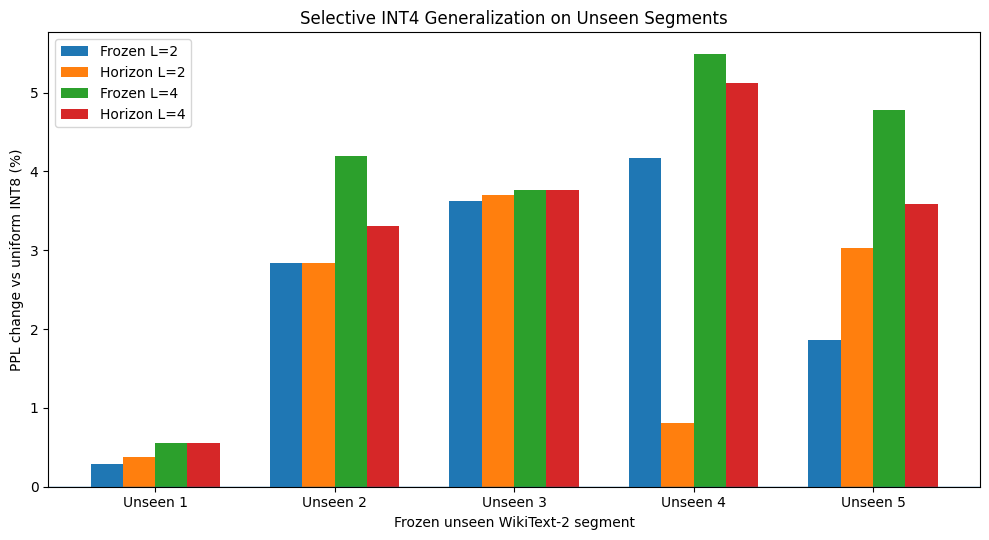

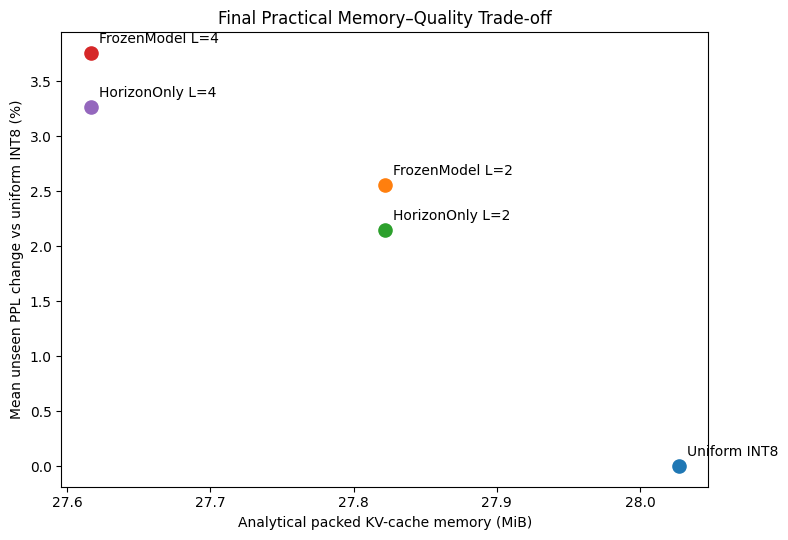

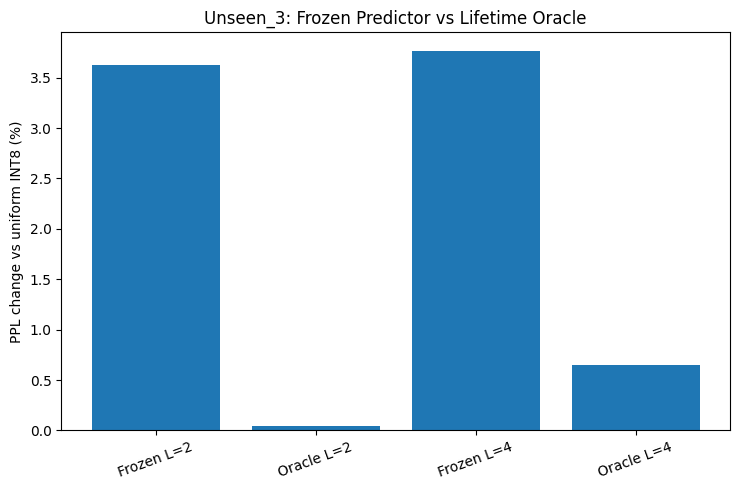


FINAL NOTEBOOK 08 CONCLUSION

Uniform INT8:
  Memory = 28.027 MiB
  Saving vs FP16 = 49.951%
  Mean unseen PPL penalty vs FP16 = 0.345%
  Worst unseen PPL penalty vs FP16 = 0.897%

Frozen selective INT4:
  L=2 -> 0.733% extra memory saving, 2.557% mean unseen PPL penalty
  L=4 -> 1.466% extra memory saving, 3.756% mean unseen PPL penalty

Oracle audit (Unseen_3):
  L=2 -> 0.040% PPL penalty
  L=4 -> 0.651% PPL penalty

FINAL PRACTICAL POLICY: UNIFORM INT8
Selective INT4 has oracle headroom, but the tested predictor does not generalize reliably.

NOTEBOOK 08 COMPLETE

Final summary: notebook08_results/final/notebook08_final_summary.md
Final JSON:    notebook08_results/final/notebook08_final_conclusion.json
Figures:       notebook08_results/final/figures
Final ZIP:     notebook08_final_results.zip

Experimental work is complete.
Next stage: final report and presentation.


In [8]:
# ============================================================
# Notebook 08 — FINAL VALIDATION NOTEBOOK
# Cell 8:
#
# FINAL ANALYSIS + FIGURES + EXPORT
#
# NO MODEL EVALUATION
# NO RETRAINING
# NO POLICY CHANGES
#
# This is the final cell of the final experimental notebook.
# ============================================================

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Final directories
# ============================================================

FINAL_DIR = (
    NB8_WORK_DIR
    / "final"
)

FIGURE_DIR = (
    FINAL_DIR
    / "figures"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. Core final numerical results
# ============================================================

# ------------------------------------------------------------
# Uniform INT8 vs FP16 across unseen segments
# ------------------------------------------------------------

baseline_pivot = (

    baseline_variation_df

    .pivot(
        index="Segment",
        columns="Selection_Method",
        values="PPL",
    )

    .reset_index()
)


baseline_pivot[
    "INT8_vs_FP16_pct"
] = (

    100.0

    * (

        baseline_pivot[
            "Uniform_INT8"
        ]

        /

        baseline_pivot[
            "FP16"
        ]

        - 1.0
    )
)


int8_mean_penalty = float(

    baseline_pivot[
        "INT8_vs_FP16_pct"
    ].mean()
)


int8_worst_penalty = float(

    baseline_pivot[
        "INT8_vs_FP16_pct"
    ].max()
)


# ------------------------------------------------------------
# Helper to retrieve aggregate practical result
# ------------------------------------------------------------

def get_aggregate(
    method,
    budget,
):

    row = (

        aggregate_unseen_df[

            (
                aggregate_unseen_df[
                    "Selection_Method"
                ]
                == method
            )

            &

            (
                aggregate_unseen_df[
                    "INT4_Budget"
                ]
                == budget
            )

        ]

        .iloc[0]
    )

    return row


frozen_l2 = get_aggregate(
    "FrozenModel",
    2
)

frozen_l4 = get_aggregate(
    "FrozenModel",
    4
)

horizon_l2 = get_aggregate(
    "HorizonOnly",
    2
)

horizon_l4 = get_aggregate(
    "HorizonOnly",
    4
)


# ------------------------------------------------------------
# Oracle audit results
# ------------------------------------------------------------

oracle_l2 = (

    audit_oracle_joint_df[

        audit_oracle_joint_df[
            "INT4_Budget"
        ]
        == 2

    ]

    .iloc[0]
)


oracle_l4 = (

    audit_oracle_joint_df[

        audit_oracle_joint_df[
            "INT4_Budget"
        ]
        == 4

    ]

    .iloc[0]
)


# ============================================================
# 3. Final headline table
# ============================================================

headline_rows = [

    {
        "Configuration":
            "Uniform FP16",

        "INT4_Budget":
            0,

        "Logical_KV_Memory_MiB":
            ALL_FP16_MEMORY_MIB,

        "Memory_Saving_vs_FP16_pct":
            0.0,

        "Memory_Saving_vs_INT8_pct":
            np.nan,

        "Unseen_Mean_PPL_Change_pct":
            -int8_mean_penalty,

        "Unseen_Worst_PPL_Change_pct":
            -float(
                baseline_pivot[
                    "INT8_vs_FP16_pct"
                ].min()
            ),

        "Interpretation":
            "Full-precision reference",
    },

    {
        "Configuration":
            "Uniform INT8",

        "INT4_Budget":
            0,

        "Logical_KV_Memory_MiB":
            UNIFORM_INT8_MEMORY_MIB,

        "Memory_Saving_vs_FP16_pct":

            100.0
            * (
                1.0
                - UNIFORM_INT8_MEMORY_MIB
                / ALL_FP16_MEMORY_MIB
            ),

        "Memory_Saving_vs_INT8_pct":
            0.0,

        "Unseen_Mean_PPL_Change_pct":
            0.0,

        "Unseen_Worst_PPL_Change_pct":
            0.0,

        "Interpretation":
            "Final practical recommendation",
    },

    {
        "Configuration":
            "Frozen predictor L=2",

        "INT4_Budget":
            2,

        "Logical_KV_Memory_MiB":
            float(
                frozen_l2[
                    "Logical_KV_Memory_MiB"
                ]
            ),

        "Memory_Saving_vs_FP16_pct":

            100.0
            * (
                1.0
                - float(
                    frozen_l2[
                        "Logical_KV_Memory_MiB"
                    ]
                )
                / ALL_FP16_MEMORY_MIB
            ),

        "Memory_Saving_vs_INT8_pct":
            float(
                frozen_l2[
                    "Memory_Saving_vs_INT8_pct"
                ]
            ),

        "Unseen_Mean_PPL_Change_pct":
            float(
                frozen_l2[
                    "Mean_Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Unseen_Worst_PPL_Change_pct":
            float(
                frozen_l2[
                    "Worst_Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Interpretation":
            "Does not transfer robustly",
    },

    {
        "Configuration":
            "Frozen predictor L=4",

        "INT4_Budget":
            4,

        "Logical_KV_Memory_MiB":
            float(
                frozen_l4[
                    "Logical_KV_Memory_MiB"
                ]
            ),

        "Memory_Saving_vs_FP16_pct":

            100.0
            * (
                1.0
                - float(
                    frozen_l4[
                        "Logical_KV_Memory_MiB"
                    ]
                )
                / ALL_FP16_MEMORY_MIB
            ),

        "Memory_Saving_vs_INT8_pct":
            float(
                frozen_l4[
                    "Memory_Saving_vs_INT8_pct"
                ]
            ),

        "Unseen_Mean_PPL_Change_pct":
            float(
                frozen_l4[
                    "Mean_Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Unseen_Worst_PPL_Change_pct":
            float(
                frozen_l4[
                    "Worst_Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Interpretation":
            "Does not transfer robustly",
    },
]


final_headline_df = pd.DataFrame(
    headline_rows
)


print(
    "============================================================"
)

print(
    "FINAL PROJECT HEADLINE RESULTS"
)

print(
    "============================================================"
)


display(
    final_headline_df
)


# ============================================================
# 4. Unseen practical-policy summary
# ============================================================

final_practical_summary_df = (

    aggregate_unseen_df[

        [
            "Selection_Method",
            "INT4_Budget",
            "Mean_Relative_PPL_vs_INT8_pct",
            "Std_Relative_PPL_vs_INT8_pct",
            "Median_Relative_PPL_vs_INT8_pct",
            "Worst_Relative_PPL_vs_INT8_pct",
            "Best_Relative_PPL_vs_INT8_pct",
            "Logical_KV_Memory_MiB",
            "Memory_Saving_vs_INT8_pct",
        ]

    ]

    .sort_values(
        [
            "INT4_Budget",
            "Selection_Method",
        ]
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "Practical unseen-segment summary"
)

print(
    "--------------------------------"
)


display(
    final_practical_summary_df
)


# ============================================================
# 5. Oracle audit summary
# ============================================================

final_oracle_summary_df = (

    audit_final_comparison_df

    .copy()

    .sort_values(
        [
            "INT4_Budget",
            "Relative_PPL_vs_INT8_pct",
        ]
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "Oracle audit summary — Unseen_3"
)

print(
    "--------------------------------"
)


display(
    final_oracle_summary_df
)


# ============================================================
# 6. Quantify oracle gap
# ============================================================

oracle_gap_rows = []


for L in VALIDATION_INT4_BUDGETS:

    frozen_row = (

        final_oracle_summary_df[

            (
                final_oracle_summary_df[
                    "Method"
                ]
                == "FrozenModel"
            )

            &

            (
                final_oracle_summary_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .iloc[0]
    )


    oracle_row = (

        final_oracle_summary_df[

            (
                final_oracle_summary_df[
                    "Method"
                ]
                == "OracleLifetime"
            )

            &

            (
                final_oracle_summary_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .iloc[0]
    )


    oracle_gap_rows.append({

        "INT4_Budget":
            L,

        "Frozen_PPL_Increase_pct":
            float(
                frozen_row[
                    "Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Oracle_PPL_Increase_pct":
            float(
                oracle_row[
                    "Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Predictor_Oracle_Gap_pp":
            float(

                frozen_row[
                    "Relative_PPL_vs_INT8_pct"
                ]

                -

                oracle_row[
                    "Relative_PPL_vs_INT8_pct"
                ]
            ),
    })


oracle_gap_df = pd.DataFrame(
    oracle_gap_rows
)


print()
print(
    "Predictor-to-oracle gap"
)

print(
    "-----------------------"
)


display(
    oracle_gap_df
)


# ============================================================
# 7. FIGURE 1
#
# Relative PPL change on each unseen segment
# for L=2 and L=4.
# ============================================================

plot_df = (

    unseen_quality_df[

        unseen_quality_df[
            "Selection_Method"
        ].isin(
            [
                "FrozenModel",
                "HorizonOnly",
            ]
        )

    ]

    .copy()
)


fig, ax = plt.subplots(
    figsize=(10, 5.5)
)


labels = [
    "Unseen 1",
    "Unseen 2",
    "Unseen 3",
    "Unseen 4",
    "Unseen 5",
]


x = np.arange(
    len(labels)
)


width = 0.18


series = [

    (
        "Frozen L=2",
        "FrozenModel",
        2,
    ),

    (
        "Horizon L=2",
        "HorizonOnly",
        2,
    ),

    (
        "Frozen L=4",
        "FrozenModel",
        4,
    ),

    (
        "Horizon L=4",
        "HorizonOnly",
        4,
    ),
]


offsets = np.array([
    -1.5,
    -0.5,
    0.5,
    1.5,
]) * width


for offset, (
    display_name,
    method,
    L,
) in zip(
    offsets,
    series
):

    values = []


    for segment_name in [
        "Unseen_1",
        "Unseen_2",
        "Unseen_3",
        "Unseen_4",
        "Unseen_5",
    ]:

        value = (

            plot_df[

                (
                    plot_df[
                        "Segment"
                    ]
                    == segment_name
                )

                &

                (
                    plot_df[
                        "Selection_Method"
                    ]
                    == method
                )

                &

                (
                    plot_df[
                        "INT4_Budget"
                    ]
                    == L
                )

            ][
                "Relative_PPL_vs_INT8_pct"
            ]

            .iloc[0]
        )


        values.append(
            value
        )


    ax.bar(
        x + offset,
        values,
        width,
        label=display_name,
    )


ax.axhline(
    0.0,
    linewidth=1,
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    labels
)

ax.set_ylabel(
    "PPL change vs uniform INT8 (%)"
)

ax.set_xlabel(
    "Frozen unseen WikiText-2 segment"
)

ax.set_title(
    "Selective INT4 Generalization on Unseen Segments"
)

ax.legend()

fig.tight_layout()


FIG1_PATH = (
    FIGURE_DIR
    / "unseen_generalization_ppl.png"
)


fig.savefig(
    FIG1_PATH,
    dpi=180,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 8. FIGURE 2
#
# Analytical memory vs mean unseen PPL degradation.
#
# Uniform INT8 + practical policies.
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)


# Uniform INT8
ax.scatter(
    [UNIFORM_INT8_MEMORY_MIB],
    [0.0],
    s=90,
)

ax.annotate(
    "Uniform INT8",
    (
        UNIFORM_INT8_MEMORY_MIB,
        0.0,
    ),
    xytext=(6, 7),
    textcoords="offset points",
)


for _, row in (
    final_practical_summary_df
    .iterrows()
):

    x_mem = float(
        row[
            "Logical_KV_Memory_MiB"
        ]
    )

    y_ppl = float(
        row[
            "Mean_Relative_PPL_vs_INT8_pct"
        ]
    )


    ax.scatter(
        [x_mem],
        [y_ppl],
        s=90,
    )


    label = (

        f"{row['Selection_Method']} "
        f"L={int(row['INT4_Budget'])}"
    )


    ax.annotate(
        label,
        (
            x_mem,
            y_ppl,
        ),
        xytext=(6, 7),
        textcoords="offset points",
    )


ax.set_xlabel(
    "Analytical packed KV-cache memory (MiB)"
)

ax.set_ylabel(
    "Mean unseen PPL change vs uniform INT8 (%)"
)

ax.set_title(
    "Final Practical Memory–Quality Trade-off"
)

fig.tight_layout()


FIG2_PATH = (
    FIGURE_DIR
    / "final_memory_quality_tradeoff.png"
)


fig.savefig(
    FIG2_PATH,
    dpi=180,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 9. FIGURE 3
#
# Frozen vs oracle-informed policy on Unseen_3.
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 5.0)
)


audit_plot = (

    final_oracle_summary_df[

        final_oracle_summary_df[
            "Method"
        ].isin(
            [
                "FrozenModel",
                "OracleLifetime",
            ]
        )

    ]

    .copy()
)


audit_labels = [
    "Frozen L=2",
    "Oracle L=2",
    "Frozen L=4",
    "Oracle L=4",
]


audit_values = []


for method, L in [

    ("FrozenModel", 2),
    ("OracleLifetime", 2),
    ("FrozenModel", 4),
    ("OracleLifetime", 4),

]:

    value = (

        audit_plot[

            (
                audit_plot[
                    "Method"
                ]
                == method
            )

            &

            (
                audit_plot[
                    "INT4_Budget"
                ]
                == L
            )

        ][
            "Relative_PPL_vs_INT8_pct"
        ]

        .iloc[0]
    )


    audit_values.append(
        value
    )


ax.bar(
    audit_labels,
    audit_values,
)


ax.set_ylabel(
    "PPL change vs uniform INT8 (%)"
)

ax.set_title(
    "Unseen_3: Frozen Predictor vs Lifetime Oracle"
)

ax.tick_params(
    axis="x",
    rotation=20,
)


fig.tight_layout()


FIG3_PATH = (
    FIGURE_DIR
    / "oracle_gap_unseen3.png"
)


fig.savefig(
    FIG3_PATH,
    dpi=180,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 10. Final quantitative conclusion
# ============================================================

final_conclusion = {

    "final_recommended_policy":
        "Uniform INT8",

    "uniform_fp16_memory_mib":
        float(
            ALL_FP16_MEMORY_MIB
        ),

    "uniform_int8_memory_mib":
        float(
            UNIFORM_INT8_MEMORY_MIB
        ),

    "uniform_int8_memory_saving_vs_fp16_pct":
        float(

            100.0

            * (

                1.0

                -

                UNIFORM_INT8_MEMORY_MIB
                / ALL_FP16_MEMORY_MIB
            )
        ),

    "uniform_int8_mean_ppl_increase_vs_fp16_unseen_pct":
        int8_mean_penalty,

    "uniform_int8_worst_ppl_increase_vs_fp16_unseen_pct":
        int8_worst_penalty,

    "frozen_L2_memory_mib":
        float(
            frozen_l2[
                "Logical_KV_Memory_MiB"
            ]
        ),

    "frozen_L2_memory_saving_vs_int8_pct":
        float(
            frozen_l2[
                "Memory_Saving_vs_INT8_pct"
            ]
        ),

    "frozen_L2_mean_ppl_increase_unseen_pct":
        float(
            frozen_l2[
                "Mean_Relative_PPL_vs_INT8_pct"
            ]
        ),

    "frozen_L2_worst_ppl_increase_unseen_pct":
        float(
            frozen_l2[
                "Worst_Relative_PPL_vs_INT8_pct"
            ]
        ),

    "frozen_L4_memory_mib":
        float(
            frozen_l4[
                "Logical_KV_Memory_MiB"
            ]
        ),

    "frozen_L4_memory_saving_vs_int8_pct":
        float(
            frozen_l4[
                "Memory_Saving_vs_INT8_pct"
            ]
        ),

    "frozen_L4_mean_ppl_increase_unseen_pct":
        float(
            frozen_l4[
                "Mean_Relative_PPL_vs_INT8_pct"
            ]
        ),

    "frozen_L4_worst_ppl_increase_unseen_pct":
        float(
            frozen_l4[
                "Worst_Relative_PPL_vs_INT8_pct"
            ]
        ),

    "oracle_audit_segment":
        AUDIT_SEGMENT,

    "oracle_L2_ppl_increase_pct":
        float(
            oracle_l2[
                "Relative_PPL_vs_INT8_pct"
            ]
        ),

    "oracle_L4_ppl_increase_pct":
        float(
            oracle_l4[
                "Relative_PPL_vs_INT8_pct"
            ]
        ),

    "audit_frozen_total_risk_spearman":
        float(
            rho_frozen_total
        ),

    "audit_v_nrmse_normalized_risk_spearman":
        float(
            rho_distortion_norm
        ),

    "audit_remaining_lifetime_total_risk_spearman":
        float(
            rho_remaining_total
        ),

    "experimental_scope":
        (
            "Qwen2.5-1.5B, WikiText-2, "
            "2048-token cache, 16-token logical pages"
        ),

    "memory_measurement":
        (
            "Analytical packed-cache memory; "
            "not physical low-bit GPU allocation"
        ),

    "final_interpretation":
        (
            "Uniform INT8 is the robust practical result. "
            "Selective INT4 shows substantial oracle headroom, "
            "but the tested frozen predictor does not generalize "
            "reliably enough to exploit it."
        ),
}


FINAL_JSON_PATH = (
    FINAL_DIR
    / "notebook08_final_conclusion.json"
)


with open(
    FINAL_JSON_PATH,
    "w"
) as f:

    json.dump(
        final_conclusion,
        f,
        indent=2,
    )


# ============================================================
# 11. Final text/Markdown summary
# ============================================================

summary_md = f"""
# Notebook 08 — Final Validation Summary

## Final practical recommendation

**Uniform INT8**

- FP16 analytical KV memory: {ALL_FP16_MEMORY_MIB:.3f} MiB
- Uniform INT8 analytical KV memory: {UNIFORM_INT8_MEMORY_MIB:.3f} MiB
- Memory saving vs FP16: {final_conclusion['uniform_int8_memory_saving_vs_fp16_pct']:.3f}%
- Mean INT8 PPL increase vs FP16 across five unseen segments:
  {int8_mean_penalty:.3f}%
- Worst INT8 PPL increase vs FP16 across five unseen segments:
  {int8_worst_penalty:.3f}%

## Frozen selective INT4 transfer

### L=2

- Memory: {float(frozen_l2['Logical_KV_Memory_MiB']):.3f} MiB
- Additional saving vs uniform INT8:
  {float(frozen_l2['Memory_Saving_vs_INT8_pct']):.3f}%
- Mean unseen PPL increase:
  {float(frozen_l2['Mean_Relative_PPL_vs_INT8_pct']):.3f}%
- Worst unseen PPL increase:
  {float(frozen_l2['Worst_Relative_PPL_vs_INT8_pct']):.3f}%

### L=4

- Memory: {float(frozen_l4['Logical_KV_Memory_MiB']):.3f} MiB
- Additional saving vs uniform INT8:
  {float(frozen_l4['Memory_Saving_vs_INT8_pct']):.3f}%
- Mean unseen PPL increase:
  {float(frozen_l4['Mean_Relative_PPL_vs_INT8_pct']):.3f}%
- Worst unseen PPL increase:
  {float(frozen_l4['Worst_Relative_PPL_vs_INT8_pct']):.3f}%

The frozen selective-INT4 predictor therefore does not provide a
robust practical improvement over uniform INT8.

## Oracle audit

On {AUDIT_SEGMENT}, oracle-informed single-page lifetime ranking followed
by joint evaluation gives:

- L=2: {float(oracle_l2['Relative_PPL_vs_INT8_pct']):.3f}% PPL increase
- L=4: {float(oracle_l4['Relative_PPL_vs_INT8_pct']):.3f}% PPL increase

The frozen policy on the same segment gives:

- L=2: 3.630% PPL increase
- L=4: 3.761% PPL increase

Therefore, substantially safer INT4 subsets exist, but the tested
inference-time predictor does not identify them reliably.

## Final conclusion

The project demonstrates that KV-cache page sensitivity is highly
heterogeneous and that oracle-informed page selection can make
low-bit quantization substantially more viable than naive assignment.

However, the tested attention, confidence, recency, and quantization-error
signals do not provide a sufficiently transferable predictor for
aggressive page-level INT4 assignment.

The strongest deployable conclusion from the current prototype is
therefore uniform INT8. It provides approximately half the analytical
FP16 KV-cache memory while remaining close to FP16 quality across the
five unseen validation segments.

Selective INT4 remains promising as future work, but requires a stronger
quantizer, a better transferable page-sensitivity estimator, or both.

Memory values are analytical packed-cache estimates. The prototype
dequantizes values into the standard FP16 DynamicCache and therefore
does not demonstrate physical low-bit GPU allocation or runtime speedup.
"""


FINAL_MD_PATH = (
    FINAL_DIR
    / "notebook08_final_summary.md"
)


FINAL_MD_PATH.write_text(
    summary_md,
    encoding="utf-8",
)


# ============================================================
# 12. Save final consolidated CSV tables
# ============================================================

final_headline_df.to_csv(

    FINAL_DIR
    / "final_headline_results.csv",

    index=False,
)


final_practical_summary_df.to_csv(

    FINAL_DIR
    / "final_practical_generalization.csv",

    index=False,
)


final_oracle_summary_df.to_csv(

    FINAL_DIR
    / "final_oracle_audit.csv",

    index=False,
)


oracle_gap_df.to_csv(

    FINAL_DIR
    / "final_predictor_oracle_gap.csv",

    index=False,
)


baseline_pivot.to_csv(

    FINAL_DIR
    / "final_int8_vs_fp16_unseen.csv",

    index=False,
)


# ============================================================
# 13. Print final conclusion
# ============================================================

print()
print(
    "============================================================"
)

print(
    "FINAL NOTEBOOK 08 CONCLUSION"
)

print(
    "============================================================"
)


print()

print(
    "Uniform INT8:"
)

print(
    f"  Memory = "
    f"{UNIFORM_INT8_MEMORY_MIB:.3f} MiB"
)

print(
    f"  Saving vs FP16 = "
    f"{final_conclusion['uniform_int8_memory_saving_vs_fp16_pct']:.3f}%"
)

print(
    f"  Mean unseen PPL penalty vs FP16 = "
    f"{int8_mean_penalty:.3f}%"
)

print(
    f"  Worst unseen PPL penalty vs FP16 = "
    f"{int8_worst_penalty:.3f}%"
)


print()

print(
    "Frozen selective INT4:"
)

print(
    f"  L=2 -> "
    f"{float(frozen_l2['Memory_Saving_vs_INT8_pct']):.3f}% "
    f"extra memory saving, "
    f"{float(frozen_l2['Mean_Relative_PPL_vs_INT8_pct']):.3f}% "
    f"mean unseen PPL penalty"
)

print(
    f"  L=4 -> "
    f"{float(frozen_l4['Memory_Saving_vs_INT8_pct']):.3f}% "
    f"extra memory saving, "
    f"{float(frozen_l4['Mean_Relative_PPL_vs_INT8_pct']):.3f}% "
    f"mean unseen PPL penalty"
)


print()

print(
    f"Oracle audit ({AUDIT_SEGMENT}):"
)

print(
    f"  L=2 -> "
    f"{float(oracle_l2['Relative_PPL_vs_INT8_pct']):.3f}% "
    f"PPL penalty"
)

print(
    f"  L=4 -> "
    f"{float(oracle_l4['Relative_PPL_vs_INT8_pct']):.3f}% "
    f"PPL penalty"
)


print()

print(
    "FINAL PRACTICAL POLICY: UNIFORM INT8"
)

print(
    "Selective INT4 has oracle headroom, "
    "but the tested predictor does not generalize reliably."
)


# ============================================================
# 14. Create FINAL ZIP
# ============================================================

ZIP_BASE = (
    "notebook08_final_results"
)


ZIP_PATH = Path(
    f"{ZIP_BASE}.zip"
)


if ZIP_PATH.exists():
    ZIP_PATH.unlink()


shutil.make_archive(

    ZIP_BASE,

    "zip",

    root_dir=str(
        NB8_WORK_DIR
    ),
)


print()
print(
    "============================================================"
)

print(
    "NOTEBOOK 08 COMPLETE"
)

print(
    "============================================================"
)

print()

print(
    f"Final summary: "
    f"{FINAL_MD_PATH}"
)

print(
    f"Final JSON:    "
    f"{FINAL_JSON_PATH}"
)

print(
    f"Figures:       "
    f"{FIGURE_DIR}"
)

print(
    f"Final ZIP:     "
    f"{ZIP_PATH}"
)

print()

print(
    "Experimental work is complete."
)

print(
    "Next stage: final report and presentation."
)

In [9]:
# ============================================================
# Download Notebook 08 final results to your computer
# ============================================================

from google.colab import files
from pathlib import Path

zip_path = Path("notebook08_final_results.zip")

if not zip_path.exists():
    raise FileNotFoundError(
        f"{zip_path} was not found. Run Cell 8 first."
    )

print(f"Downloading: {zip_path}")
print(f"Size: {zip_path.stat().st_size / 1024**2:.2f} MiB")

files.download(str(zip_path))

Downloading: notebook08_final_results.zip
Size: 0.19 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>